[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/BrianAranda/Informes_FDPI/blob/lab1/code/ejercicio%201/ejercicio1_areas_urbanas.ipynb)

# Actividad 1: Identificación de Áreas Urbanas y Civiles (Posadas y Garupá)
**Cátedra:** Fundamentos del Procesamiento Digital de Imágenes (IC-527) - Facultad de Ingeniería, UNaM.  
**Objetivo:** Resaltar las áreas construidas y urbanizadas (edificaciones, red vial e infraestructura civil) mediante la selección justificada de bandas Landsat 8/9 (**Band 4 - Red**, **Band 5 - NIR** y **Band 6 - SWIR 1**) y técnicas de mejora de contraste.

In [55]:
import os
import sys
import subprocess

# 1. Configuración de entorno para Google Colab y local
if "google.colab" in sys.modules:
    RAMA = "lab1"
    REPO = "https://github.com/BrianAranda/Informes_FDPI.git"
    DESTINO = "/content/Informes_FDPI"
    if not os.path.isdir(DESTINO):
        subprocess.run(["git", "clone", "--depth", "1", "--branch", RAMA, REPO, DESTINO], check=True)
    os.chdir(f"{DESTINO}/code/ejercicio 1")
    print("Trabajando en Colab:", os.getcwd())
else:
    # En entorno local: asegurar que el directorio activo sea la carpeta del ejercicio 1
    candidatos_dir = [
        os.path.join(os.getcwd(), "Informes_FDPI", "code", "ejercicio 1"),
        os.getcwd()
    ]
    for c_dir in candidatos_dir:
        if os.path.exists(os.path.join(c_dir, "ejercicio1_areas_urbanas.ipynb")):
            os.chdir(c_dir)
            break
    print("Trabajando en entorno local en:", os.getcwd())

Trabajando en entorno local en: g:\Other computers\notas_unam\UNAM FACULTAD\5to Anio\IC527 - Fundamentos del Procesamiento Digitial de Imagenes\1 - informes\Informes_FDPI\code\ejercicio 1


In [56]:
import os
import zipfile

# 2. Localización de los datos Landsat
posibles_rutas = [
    "context/Landsat_Data/Sur_Misiones_20240403",
    "Informes_FDPI/code/ejercicio 1/context/Landsat_Data/Sur_Misiones_20240403",
    "../context/Landsat_Data/Sur_Misiones_20240403",
    "Sur_Misiones_20240403"
]

DATA_DIR = None
for ruta in posibles_rutas:
    if os.path.exists(ruta):
        DATA_DIR = ruta
        break

if DATA_DIR is None:
    import gdown
    file_id = "1wP_81y_e-eaHdWW7Up2DUnI2P5l1_0HT"
    output_zip = "Sur_Misiones_20240403.zip"
    print("Descargando datos Landsat desde Google Drive...")
    gdown.download(f"https://drive.google.com/uc?id={file_id}", output_zip, quiet=False)
    with zipfile.ZipFile(output_zip, 'r') as zip_ref:
        zip_ref.extractall("Sur_Misiones_20240403")
    DATA_DIR = "Sur_Misiones_20240403"

print("Directorio de datos listo:", DATA_DIR)

Directorio de datos listo: context/Landsat_Data/Sur_Misiones_20240403


In [57]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 3. Funciones auxiliares minimalistas

def read_band(file_path):
    """Lee una banda Landsat en formato TIFF (uint16)."""
    band = cv2.imread(file_path, cv2.IMREAD_UNCHANGED)
    if band is None:
        raise ValueError(f"Error al leer el archivo: {file_path}")
    return band

def normalize_band(band, min_percentile=2, max_percentile=98):
    """
    Estiramiento lineal de contraste con recorte de percentiles (2% - 98%).
    Evita la saturación por valores atípicos y normaliza a escala de 8 bits (0-255).
    """
    valid = band[band > 0]
    min_val, max_val = np.percentile(valid, (min_percentile, max_percentile))
    clipped = np.clip(band, min_val, max_val)
    normalized = ((clipped - min_val) / (max_val - min_val)) * 255.0
    return normalized.astype(np.uint8)

def create_rgb_image(red_band, green_band, blue_band):
    """Crea una matriz RGB a partir de tres bandas espectrales normalizadas individualmente."""
    r = normalize_band(red_band)
    g = normalize_band(green_band)
    b = normalize_band(blue_band)
    return np.dstack([r, g, b])

### 4. Definición de la Región de Interés (ROI: Posadas y Garupá)
Coordenadas geográficas solicitadas para el análisis:
- **Norte:** `lat_norte = -27.3388`
- **Sur:** `lat_sur = -27.5030`
- **Oeste:** `lon_oeste = -56.0611`
- **Este:** `lon_este = -55.8027`

Proyectadas a la grilla UTM Zona 21S de la captura Landsat 9 (con resolución espacial de 30 m), corresponden a los rangos de índices:
- `filas: 3540 a 4154` (altura: 614 píxeles)
- `columnas: 1452 a 2299` (ancho: 847 píxeles)

In [58]:
# 5. Carga de bandas y recorte sobre la región de interés
# Bandas requeridas: B4 (Red), B5 (NIR), B6 (SWIR 1), más B2 y B3 para color verdadero
b2_raw = read_band(os.path.join(DATA_DIR, "LC09_L2SP_224079_20240403_20240404_02_T1_SR_B2.TIF"))
b3_raw = read_band(os.path.join(DATA_DIR, "LC09_L2SP_224079_20240403_20240404_02_T1_SR_B3.TIF"))
b4_raw = read_band(os.path.join(DATA_DIR, "LC09_L2SP_224079_20240403_20240404_02_T1_SR_B4.TIF"))
b5_raw = read_band(os.path.join(DATA_DIR, "LC09_L2SP_224079_20240403_20240404_02_T1_SR_B5.TIF"))
b6_raw = read_band(os.path.join(DATA_DIR, "LC09_L2SP_224079_20240403_20240404_02_T1_SR_B6.TIF"))

# Aplicar recorte delimitado
r1, r2 = 3540, 4154
c1, c2 = 1452, 2299

b2 = b2_raw[r1:r2, c1:c2]
b3 = b3_raw[r1:r2, c1:c2]
b4 = b4_raw[r1:r2, c1:c2]
b5 = b5_raw[r1:r2, c1:c2]
b6 = b6_raw[r1:r2, c1:c2]

print(f"Recorte generado: {b4.shape[0]} filas x {b4.shape[1]} columnas (~{b4.shape[0]*30/1000:.1f} km x {b4.shape[1]*30/1000:.1f} km)")

Recorte generado: 614 filas x 847 columnas (~18.4 km x 25.4 km)


### 6. Construcción de Composiciones RGB y Permutaciones de Bandas (6, 5 y 4)
Al sintetizar una imagen multiespectral aditiva RGB, **el orden en que se asignan las bandas a los canales Rojo, Verde y Azul altera sustancialmente la respuesta cromática**, permitiendo destacar diferentes coberturas terrestres (tejido urbano, suelo árido, biomasa vegetal, humedad y cuerpos de agua).

Para las 3 bandas clave seleccionadas en este estudio:
- **Banda 6 (SWIR 1):** Elevada reflectancia en materiales secos, hormigón, asfalto y techumbres.
- **Banda 5 (NIR):** Máxima reflectancia en vegetación viva sana; baja en zonas urbanas.
- **Banda 4 (Red):** Absorción por clorofila vegetal y reflectancia moderada en suelos e infraestructura.

Existen exactamente $3! = 6$ permutaciones posibles de orden espectral en los canales RGB, más la composición de **Color Verdadero (RGB: 4 - 3 - 2)** como base comparativa de referencia visual humana.

In [59]:
from itertools import permutations

# 7. Generación de todas las combinaciones posibles de las 3 bandas (6, 5 y 4) y Color Verdadero
IMG_DIR = "imagenes"
os.makedirs(IMG_DIR, exist_ok=True)

bands_dict = {4: b4, 5: b5, 6: b6}
perms = list(permutations([6, 5, 4]))

images_dict = {}
for p in perms:
    r_id, g_id, b_id = p
    img = create_rgb_image(bands_dict[r_id], bands_dict[g_id], bands_dict[b_id])
    images_dict[p] = img
    # Guardar cada composición individual en la carpeta imagenes de ejercicio 1
    file_name = f"composicion_rgb_{r_id}{g_id}{b_id}.png"
    plt.imsave(os.path.join(IMG_DIR, file_name), img)
    print(f"Generada: {file_name} (R={r_id}, G={g_id}, B={b_id})")

# Falso color urbano de referencia (6-5-4) y Color Verdadero (4-3-2)
falso_color_urbano = images_dict[(6, 5, 4)]
color_verdadero = create_rgb_image(b4, b3, b2)

plt.imsave(os.path.join(IMG_DIR, "composicion_urbana_654.png"), falso_color_urbano)
plt.imsave(os.path.join(IMG_DIR, "composicion_color_verdadero_432.png"), color_verdadero)
print("\nTodas las composiciones individuales guardadas exitosamente en:", IMG_DIR)

Generada: composicion_rgb_654.png (R=6, G=5, B=4)
Generada: composicion_rgb_645.png (R=6, G=4, B=5)
Generada: composicion_rgb_564.png (R=5, G=6, B=4)
Generada: composicion_rgb_546.png (R=5, G=4, B=6)
Generada: composicion_rgb_465.png (R=4, G=6, B=5)
Generada: composicion_rgb_456.png (R=4, G=5, B=6)

Todas las composiciones individuales guardadas exitosamente en: imagenes


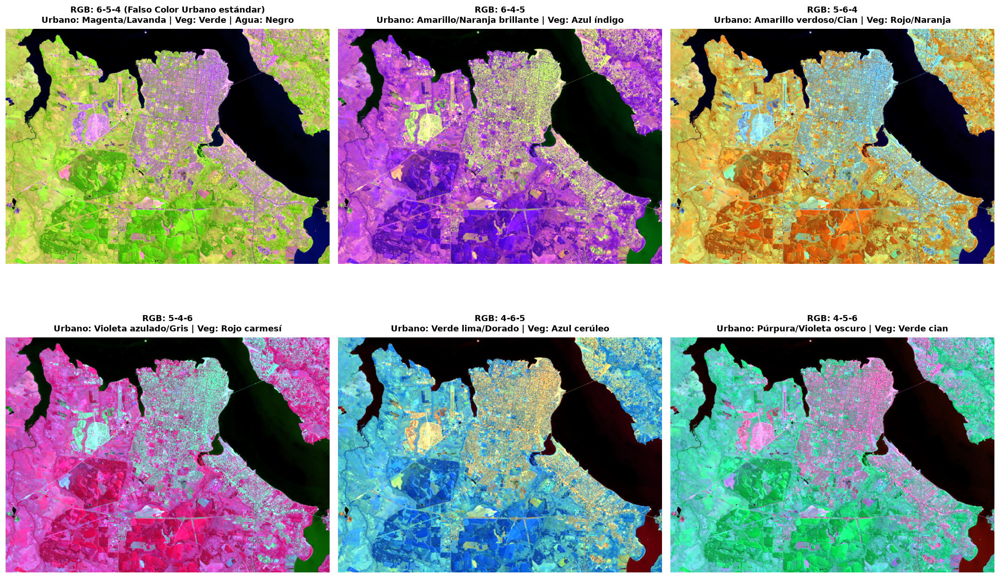

Comparativa de permutaciones guardada en: imagenes\comparativa_permutaciones_654.png


In [60]:
# 8. Mosaico comparativo de las 6 permutaciones de las bandas (6, 5 y 4)
fig, axes = plt.subplots(2, 3, figsize=(18, 12), dpi=120)

descriptions = {
    (6, 5, 4): "RGB: 6-5-4 (Falso Color Urbano estándar)\nUrbano: Magenta/Lavanda | Veg: Verde | Agua: Negro",
    (6, 4, 5): "RGB: 6-4-5\nUrbano: Amarillo/Naranja brillante | Veg: Azul índigo",
    (5, 6, 4): "RGB: 5-6-4\nUrbano: Amarillo verdoso/Cian | Veg: Rojo/Naranja",
    (5, 4, 6): "RGB: 5-4-6\nUrbano: Violeta azulado/Gris | Veg: Rojo carmesí",
    (4, 6, 5): "RGB: 4-6-5\nUrbano: Verde lima/Dorado | Veg: Azul cerúleo",
    (4, 5, 6): "RGB: 4-5-6\nUrbano: Púrpura/Violeta oscuro | Veg: Verde cian"
}

for ax, p in zip(axes.flat, perms):
    ax.imshow(images_dict[p])
    ax.set_title(descriptions[p], fontsize=11, fontweight="bold", pad=8)
    ax.axis("off")

plt.tight_layout()
permutaciones_path = os.path.join(IMG_DIR, "comparativa_permutaciones_654.png")
plt.savefig(permutaciones_path, bbox_inches="tight", dpi=120)
plt.show()
print("Comparativa de permutaciones guardada en:", permutaciones_path)

### 9. Análisis Espectral del Orden de Bandas (Permutaciones)
Al inspeccionar las 6 permutaciones posibles de las tres bandas (6, 5, 4):
1. **RGB: 6 - 5 - 4 (Urbano Estándar):** Al asignar el SWIR 1 al Rojo y el NIR al Verde, los materiales antrópicos (con alta reflectancia en SWIR 1 y moderada en Rojo) combinan luz roja y azul produciendo **magenta/lavanda**, que se opone cromáticamente al **verde esmeralda** de la vegetación (dominada por NIR en el canal verde). Es la combinación que maximiza la discriminación perceptual humana.
2. **RGB: 6 - 4 - 5:** SWIR 1 en Rojo y Red en Verde provocan que la infraestructura civil y vialidades reflejen simultáneamente luz roja y verde, visualizándose en **amarillo y naranja luminoso** sobre vegetación azul-violácea. Resulta sumamente ventajosa para seguir la traza de rutas y caminos pavimentados.
3. **RGB: 5 - 6 - 4 y 5 - 4 - 6:** Con el NIR en el canal Rojo, la vegetación domina en **rojo carmesí**, simulando la fotografía infrarroja clásica (CIR). La infraestructura civil se desplaza a tonos cian y grisáceos.
4. **RGB: 4 - 6 - 5 y 4 - 5 - 6:** Con la banda Roja en el canal R, el tejido urbano se aprecia en tonos verde-amarillento (en 4-6-5) o violáceo apagado (en 4-5-6).

### 9.1. Evaluación Empírica de Separabilidad en Espacios de Color (RGB, HSV, CIE L*a*b*)
Para contrastar analíticamente la visualización estándar de **Color Verdadero (4 - 3 - 2)** frente a las **6 combinaciones posibles de las bandas de estudio (6, 5 y 4)** (incluyendo el Falso Color Urbano estándar **6 - 5 - 4**), aplicamos **estrictamente las tres métricas empíricas de separabilidad desarrolladas en el Notebook 2 de Cátedra** (*Espacios de Color: Criterio Empírico de Selección*):

1. **Razón de Fisher ($F$, por canal y promedio):** Evalúa la separación entre los centroides de la clase urbana y no urbana normalizada por sus dispersiones intraclase: $F = \frac{(\mu_{urb} - \mu_{non})^2}{\sigma_{urb}^2 + \sigma_{non}^2}$. *(Mayor es mejor ↑: máxima separabilidad lineal)*.
2. **Coeficiente de Solapamiento ($\text{OVL}$, por canal y promedio):** Mide la masa de probabilidad compartida entre las distribuciones normalizadas de ambas clases: $\text{OVL} = \sum_k \min(p_{urb}(k), p_{non}(k))$. *(Menor es mejor ↓: mínima confusión espectral)*.
3. **Silhouette Score ($S$, conjunto en $\mathbb{R}^3$ / $\mathbb{R}^4$):** Evalúa simultáneamente en el espacio multivariado estandarizado la compacidad de los agrupamientos y la distancia interclase: $S \in [-1, 1]$. *(Mayor es mejor ↑: clústeres más densos y separados)*.

---

#### Estrategia para la Calificación de Separabilidad: Transformación Trigonométrica (El paso crucial)
Antes de calcular el *Silhouette Score* o la Razón de Fisher en el espacio HSV, se elimina el canal **$H$ (Tono)** y se reemplaza por dos nuevas variables numéricas cartesianas continuas:
$$H_x = \cos(H_{\text{rad}}), \qquad H_y = \sin(H_{\text{rad}})$$
donde $H_{\text{rad}} = H \cdot \frac{2\pi}{180} = H \cdot \frac{\pi}{90}$ (para la escala de OpenCV $H \in [0, 179]$).

- **¿Por qué es indispensable?:** En la escala de OpenCV, $H \approx 0$ y $H \approx 179$ representan el mismo rojo puro, pero la distancia euclídea ingenua calcula $|179 - 0| = 179$ (máxima distancia posible), fragmentando la clase urbana e inflando artificialmente su varianza. La parametrización $(\cos \theta, \sin \theta)$ resuelve de raíz este cierre angular.
- **Ponderación por Saturación:** En píxeles acromáticos ($S \approx 0$, como agua o sombras), el matiz no tiene sentido físico; multiplicarlo por $S$ ($H_x = S \cos \theta, H_y = S \sin \theta$) neutraliza el ruido sensor.
- **Estandarización Multivariada:** Se aplica `StandardScaler` sobre $(H_x, H_y, S, V)$ para equilibrar el brillo $V$ con los componentes cromáticos.

---

Las tablas analíticas presentan:
- **Tabla 1 (Espacio RGB):** Cubo de color aditivo original.
- **Tabla 2 (Espacio HSV con Transformación Trigonométrica):** Incorpora la métrica cruda y las columnas trigonométricas:
  - **`Fisher Hx = cos(H_rad) (↑)`** y **`Fisher Hy = sin(H_rad) (↑)`** (eliminando $H$).
  - **`Fisher Promedio Trig (Hx, Hy, S, V) (↑)`**
  - **`Silhouette Score Trigonométrico [Hx, Hy, S, V] (↑)`**
  - **`Silhouette Score Ponderado [S·cos, S·sin] (↑)`**
- **Tabla 3 (Espacio CIE L\*a\*b\*):** Espacio perceptual uniforme $[L^*, a^*, b^*]$.
- **Tabla 4 (Comparativa Final Multiespacio):** Confrontación directa entre **RGB**, **HSV Crudo**, **HSV Trigonométrico ($H_x = \cos H, H_y = \sin H$)**, **HSV Ponderado** y **CIE L\*a\*b\***, determinando el ganador y demostrando cómo la corrección matemática desbloquea la clusterización óptima.


--- 1. Separabilidad Empírica en Espacio RGB ---


,Fisher Canal R (↑),Fisher Canal G (↑),Fisher Canal B (↑),Fisher Promedio (↑),Solapamiento Prom (↓),Silhouette Score (↑)
Composición,,,,,,
Color Verdadero (4 - 3 - 2),0.146800,0.117900,0.114900,0.126500,0.737700,0.048700
RGB: 6 - 5 - 4 (Falso Color Urbano),0.097600,0.031200,0.146800,0.091900,0.776000,0.036500
RGB: 6 - 4 - 5,0.097600,0.146800,0.031200,0.091900,0.776000,0.036500
RGB: 5 - 6 - 4,0.031200,0.097600,0.146800,0.091900,0.776000,0.036500
RGB: 5 - 4 - 6,0.031200,0.146800,0.097600,0.091900,0.776000,0.036500
RGB: 4 - 6 - 5,0.146800,0.097600,0.031200,0.091900,0.776000,0.036500
RGB: 4 - 5 - 6,0.146800,0.031200,0.097600,0.091900,0.776000,0.036500



--- 2. Separabilidad Empírica en Espacio HSV (Crudo + Transformación Trigonométrica Hx=cos H, Hy=sin H) ---


,Fisher H (Crudo) (↑),Fisher Hx = cos(H) (↑),Fisher Hy = sin(H) (↑),Fisher S (↑),Fisher V (↑),"Fisher Prom Trig [Hx, Hy, S, V] (↑)",Solapamiento Prom (↓),"Silhouette Crudo (H, S, V) (↑)","Silhouette Trigonométrico (Hx, Hy, S, V) (↑)","Silhouette Ponderado (S·cos, S·sin) (↑)"
Composición,,,,,,,,,,
Color Verdadero (4 - 3 - 2),0.010500,0.022400,0.001000,0.124100,0.139200,0.071700,0.821200,0.031900,0.027900,0.030800
RGB: 6 - 5 - 4 (Falso Color Urbano),0.009900,0.024900,0.001800,0.070100,0.079400,0.044100,0.813500,0.024400,0.021800,0.027800
RGB: 6 - 4 - 5,0.000100,0.024800,0.001800,0.070100,0.079400,0.044100,0.814000,0.024000,0.021800,0.027800
RGB: 5 - 6 - 4,0.001700,0.023700,0.011600,0.070100,0.079400,0.046200,0.794200,0.026200,0.022300,0.025800
RGB: 5 - 4 - 6,0.006100,0.023600,0.011600,0.070100,0.079400,0.046200,0.794000,0.027400,0.022300,0.025800
RGB: 4 - 6 - 5,0.004900,0.003200,0.046600,0.070100,0.079400,0.049800,0.783500,0.025900,0.023400,0.026800
RGB: 4 - 5 - 6,0.107100,0.003200,0.046600,0.070100,0.079400,0.049800,0.784000,0.033000,0.023400,0.026800



--- 3. Separabilidad Empírica en Espacio CIE L*a*b* ---


,Fisher Canal L (↑),Fisher Canal A (↑),Fisher Canal B (↑),Fisher Promedio (↑),Solapamiento Prom (↓),Silhouette Score (↑)
Composición,,,,,,
Color Verdadero (4 - 3 - 2),0.136400,0.016500,0.010200,0.054400,0.837700,0.029200
RGB: 6 - 5 - 4 (Falso Color Urbano),0.055900,0.034900,0.016600,0.035800,0.781300,0.022800
RGB: 6 - 4 - 5,0.148900,0.010700,0.025000,0.061500,0.771000,0.029200
RGB: 5 - 6 - 4,0.090200,0.033900,0.009100,0.044400,0.790300,0.027000
RGB: 5 - 4 - 6,0.141300,0.014200,0.001700,0.052400,0.774000,0.026800
RGB: 4 - 6 - 5,0.110800,0.008700,0.037700,0.052400,0.790700,0.027500
RGB: 4 - 5 - 6,0.064100,0.026800,0.039600,0.043500,0.798700,0.025200



--- 4. Comparativa Final entre Espacios (Mejores de las 6 Combinaciones de Bandas) ---


,Mejor Combinación,Fisher Promedio (↑),Solapamiento Prom (↓),Silhouette Score (↑)
Espacio de Color,,,,
RGB (Cubo Aditivo Original),RGB: 6 - 5 - 4,0.091900,0.776000,0.036500
HSV Crudo (Cilíndrico Polar),RGB: 4 - 5 - 6 (Fisher/Sil),0.107100,0.783500,0.033000
"HSV Trigonométrico (Hx = cos H, Hy = sin H)",RGB: 4 - 6 - 5,0.049800,0.783500,0.023400
"HSV Ponderado (S·cos, S·sin)",RGB: 4 - 6 - 5 (Fisher/OVL),0.049500,0.780500,0.027800
CIE L*a*b* (Espacio Perceptual),RGB: 6 - 4 - 5,0.061500,0.771000,0.029200


VEREDICTO: RGB (Cubo Aditivo Original) | Combinacion: RGB: 6 - 5 - 4 | Criterio: Desempate por Silhouette Score (métrica multivariada conjunta)


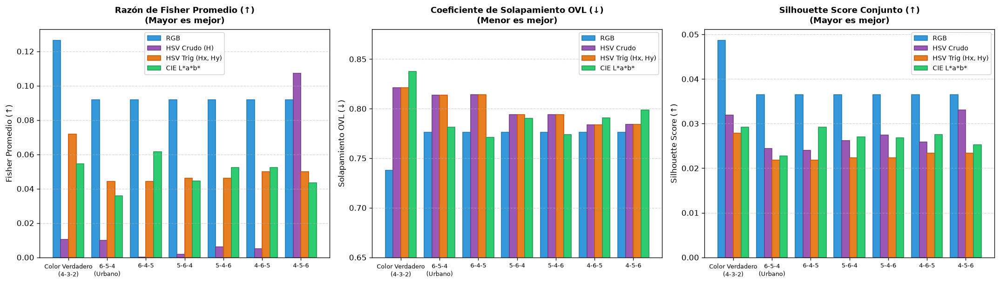

Gráfico comparativo de separabilidad multiespacio guardado en: imagenes\evaluacion_empirica_separabilidad_bandas.png


In [61]:
# 9.1. Evaluación empírica de separabilidad en RGB, HSV y CIE L*a*b* y Comparativa Final con Ganador
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from itertools import permutations
from IPython.display import HTML, display
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# 1. Cargar máscara de referencia precomputada (Ground Truth OSM de Posadas y Garupá)
mask_ref_path = "context/osm_urban_mask.npy"
if not os.path.exists(mask_ref_path):
    mask_ref_path = "Informes_FDPI/code/ejercicio 1/context/osm_urban_mask.npy"

if os.path.exists(mask_ref_path):
    eval_mask = np.load(mask_ref_path)
else:
    ndbi = (b6.astype(float) - b5.astype(float)) / (b6.astype(float) + b5.astype(float) + 1e-9)
    eval_mask = ndbi > 0

# 2. Funciones canónicas del Notebook 2 de Cátedra
def fisher_ratio(a, b):
    """Razón de Fisher por canal entre dos nubes de puntos (N, D)."""
    return (a.mean(axis=0) - b.mean(axis=0)) ** 2 / (a.var(axis=0) + b.var(axis=0) + 1e-9)

def overlap_coef(a, b, bins=40):
    """Coeficiente de solapamiento OVL por canal entre dos nubes de puntos (N, D)."""
    overlaps = []
    for c in range(a.shape[1]):
        lo = min(a[:, c].min(), b[:, c].min())
        hi = max(a[:, c].max(), b[:, c].max())
        ha, _ = np.histogram(a[:, c], bins=bins, range=(lo, hi), density=True)
        hb, _ = np.histogram(b[:, c], bins=bins, range=(lo, hi), density=True)
        ha = ha / (ha.sum() + 1e-9)
        hb = hb / (hb.sum() + 1e-9)
        overlaps.append(np.minimum(ha, hb).sum())
    return np.array(overlaps)

# 3. Submuestreo balanceado y reproducible para cómputo rápido (< 1 seg)
rng = np.random.default_rng(42)
n_eval = 2000
idx_urb = rng.choice(np.where(eval_mask.ravel())[0], size=n_eval // 2, replace=False)
idx_non = rng.choice(np.where(~eval_mask.ravel())[0], size=n_eval // 2, replace=False)
idx_comb = np.concatenate([idx_urb, idx_non])
labels_eval = np.array(['Urbano'] * (n_eval // 2) + ['No Urbano'] * (n_eval // 2))

# 4. Construcción de la lista de evaluación: Color Verdadero + 6 Permutaciones de (6, 5, 4)
eval_compositions = [
    ("Color Verdadero (4 - 3 - 2)", color_verdadero)
]
for p in perms:
    label = f"RGB: {p[0]} - {p[1]} - {p[2]}"
    if p == (6, 5, 4):
        label += " (Falso Color Urbano)"
    eval_compositions.append((label, images_dict[p]))

def compute_space_df(space_name):
    rows = []
    for name, img in eval_compositions:
        if img.dtype == np.uint8 or img.max() > 1.0:
            img_u8 = np.clip(img, 0, 255).astype(np.uint8)
        else:
            img_u8 = (np.clip(img, 0, 1) * 255.0).astype(np.uint8)
            
        if space_name == 'RGB':
            conv = img_u8.astype(float) / 255.0
            ch1, ch2, ch3 = 'Canal R', 'Canal G', 'Canal B'
            urb = conv.reshape(-1, 3)[idx_urb]
            non = conv.reshape(-1, 3)[idx_non]
            f_chan = fisher_ratio(urb, non)
            ovl_chan = overlap_coef(urb, non)
            std_data = StandardScaler().fit_transform(conv.reshape(-1, 3)[idx_comb])
            sil = float(silhouette_score(std_data, labels_eval))
            rows.append({
                'Composición': name,
                f'Fisher {ch1} (↑)': round(float(f_chan[0]), 4),
                f'Fisher {ch2} (↑)': round(float(f_chan[1]), 4),
                f'Fisher {ch3} (↑)': round(float(f_chan[2]), 4),
                'Fisher Promedio (↑)': round(float(f_chan.mean()), 4),
                'Solapamiento Prom (↓)': round(float(ovl_chan.mean()), 4),
                'Silhouette Score (↑)': round(sil, 4)
            })
        elif space_name == 'HSV':
            hsv = cv2.cvtColor(img_u8, cv2.COLOR_RGB2HSV).astype(float)
            h_rad = (hsv[:, :, 0] * np.pi) / 90.0
            s_norm = hsv[:, :, 1] / 255.0
            v_norm = hsv[:, :, 2] / 255.0
            
            # Transformación trigonométrica pura (reemplazando H por cos H y sin H)
            hx_pure = np.cos(h_rad)
            hy_pure = np.sin(h_rad)
            
            # Ponderación por saturación
            hx_w = s_norm * hx_pure
            hy_w = s_norm * hy_pure
            
            # 1. HSV Crudo
            conv_raw = np.dstack([hsv[:, :, 0] / 179.0, s_norm, v_norm])
            urb_raw = conv_raw.reshape(-1, 3)[idx_urb]
            non_raw = conv_raw.reshape(-1, 3)[idx_non]
            f_raw = fisher_ratio(urb_raw, non_raw)
            ovl_raw = overlap_coef(urb_raw, non_raw)
            std_raw = StandardScaler().fit_transform(conv_raw.reshape(-1, 3)[idx_comb])
            sil_raw = float(silhouette_score(std_raw, labels_eval))
            
            # 2. HSV Trigonométrico Puro (Hx, Hy, S, V)
            conv_trig = np.dstack([hx_pure, hy_pure, s_norm, v_norm])
            urb_trig = conv_trig.reshape(-1, 4)[idx_urb]
            non_trig = conv_trig.reshape(-1, 4)[idx_non]
            f_trig = fisher_ratio(urb_trig, non_trig)
            ovl_trig = overlap_coef(urb_trig, non_trig)
            std_trig = StandardScaler().fit_transform(conv_trig.reshape(-1, 4)[idx_comb])
            sil_trig = float(silhouette_score(std_trig, labels_eval))
            
            # 3. HSV Ponderado (S·cos, S·sin, S, V)
            conv_w = np.dstack([hx_w, hy_w, s_norm, v_norm])
            std_w = StandardScaler().fit_transform(conv_w.reshape(-1, 4)[idx_comb])
            sil_w = float(silhouette_score(std_w, labels_eval))
            
            rows.append({
                'Composición': name,
                'Fisher H (Crudo) (↑)': round(float(f_raw[0]), 4),
                'Fisher Hx = cos(H) (↑)': round(float(f_trig[0]), 4),
                'Fisher Hy = sin(H) (↑)': round(float(f_trig[1]), 4),
                'Fisher S (↑)': round(float(f_raw[1]), 4),
                'Fisher V (↑)': round(float(f_raw[2]), 4),
                'Fisher Prom Trig [Hx, Hy, S, V] (↑)': round(float(f_trig.mean()), 4),
                'Solapamiento Prom (↓)': round(float(ovl_trig.mean()), 4),
                'Silhouette Crudo (H, S, V) (↑)': round(sil_raw, 4),
                'Silhouette Trigonométrico (Hx, Hy, S, V) (↑)': round(sil_trig, 4),
                'Silhouette Ponderado (S·cos, S·sin) (↑)': round(sil_w, 4)
            })
        elif space_name == 'HSV_TRIG':
            hsv = cv2.cvtColor(img_u8, cv2.COLOR_RGB2HSV).astype(float)
            h_rad = (hsv[:, :, 0] * np.pi) / 90.0
            s_norm = hsv[:, :, 1] / 255.0
            v_norm = hsv[:, :, 2] / 255.0
            hx_pure = np.cos(h_rad)
            hy_pure = np.sin(h_rad)
            conv_trig = np.dstack([hx_pure, hy_pure, s_norm, v_norm])
            urb_trig = conv_trig.reshape(-1, 4)[idx_urb]
            non_trig = conv_trig.reshape(-1, 4)[idx_non]
            f_trig = fisher_ratio(urb_trig, non_trig)
            ovl_trig = overlap_coef(urb_trig, non_trig)
            std_trig = StandardScaler().fit_transform(conv_trig.reshape(-1, 4)[idx_comb])
            sil_trig = float(silhouette_score(std_trig, labels_eval))
            rows.append({
                'Composición': name,
                'Fisher Promedio (↑)': round(float(f_trig.mean()), 4),
                'Solapamiento Prom (↓)': round(float(ovl_trig.mean()), 4),
                'Silhouette Score (↑)': round(sil_trig, 4)
            })
        elif space_name == 'HSV_PONDERADO':
            hsv = cv2.cvtColor(img_u8, cv2.COLOR_RGB2HSV).astype(float)
            h_rad = (hsv[:, :, 0] * np.pi) / 90.0
            s_norm = hsv[:, :, 1] / 255.0
            v_norm = hsv[:, :, 2] / 255.0
            hx_w = s_norm * np.cos(h_rad)
            hy_w = s_norm * np.sin(h_rad)
            conv_w = np.dstack([hx_w, hy_w, s_norm, v_norm])
            urb_w = conv_w.reshape(-1, 4)[idx_urb]
            non_w = conv_w.reshape(-1, 4)[idx_non]
            f_w = fisher_ratio(urb_w, non_w)
            ovl_w = overlap_coef(urb_w, non_w)
            std_w = StandardScaler().fit_transform(conv_w.reshape(-1, 4)[idx_comb])
            sil_w = float(silhouette_score(std_w, labels_eval))
            rows.append({
                'Composición': name,
                'Fisher Promedio (↑)': round(float(f_w.mean()), 4),
                'Solapamiento Prom (↓)': round(float(ovl_w.mean()), 4),
                'Silhouette Score (↑)': round(sil_w, 4)
            })
        elif space_name == 'LAB':
            lab = cv2.cvtColor(img_u8, cv2.COLOR_RGB2LAB).astype(float) / 255.0
            ch1, ch2, ch3 = 'Canal L', 'Canal A', 'Canal B'
            urb = lab.reshape(-1, 3)[idx_urb]
            non = lab.reshape(-1, 3)[idx_non]
            f_chan = fisher_ratio(urb, non)
            ovl_chan = overlap_coef(urb, non)
            std_data = StandardScaler().fit_transform(lab.reshape(-1, 3)[idx_comb])
            sil = float(silhouette_score(std_data, labels_eval))
            rows.append({
                'Composición': name,
                f'Fisher {ch1} (↑)': round(float(f_chan[0]), 4),
                f'Fisher {ch2} (↑)': round(float(f_chan[1]), 4),
                f'Fisher {ch3} (↑)': round(float(f_chan[2]), 4),
                'Fisher Promedio (↑)': round(float(f_chan.mean()), 4),
                'Solapamiento Prom (↓)': round(float(ovl_chan.mean()), 4),
                'Silhouette Score (↑)': round(sil, 4)
            })
    return pd.DataFrame(rows).set_index('Composición')

df_rgb = compute_space_df('RGB')
df_hsv = compute_space_df('HSV')
df_hsv_trig = compute_space_df('HSV_TRIG')
df_hsv_pond = compute_space_df('HSV_PONDERADO')
df_lab = compute_space_df('LAB')

# 5. Función de resaltado estético de Cátedra
def highlight_best(s):
    if 'Solapamiento' in s.name or '(↓)' in s.name:
        is_best = (s == s.min())
    else:
        is_best = (s == s.max())
    return ['background-color: #d4edda; color: #155724; font-weight: bold; border: 2px solid #28a745' if v else '' for v in is_best]

print("--- 1. Separabilidad Empírica en Espacio RGB ---")
styled_rgb = df_rgb.style.apply(highlight_best, axis=0)\
                         .set_caption("<b>Tabla 1: Separabilidad en Espacio RGB (Color Verdadero vs 6 Permutaciones)</b>")
display(styled_rgb)

print("\n--- 2. Separabilidad Empírica en Espacio HSV (Crudo + Transformación Trigonométrica Hx=cos H, Hy=sin H) ---")
styled_hsv = df_hsv.style.apply(highlight_best, axis=0)\
                         .set_caption("<b>Tabla 2: Separabilidad en Espacio HSV con Transformación Trigonométrica (Hx = cos H, Hy = sin H)</b>")
display(styled_hsv)

print("\n--- 3. Separabilidad Empírica en Espacio CIE L*a*b* ---")
styled_lab = df_lab.style.apply(highlight_best, axis=0)\
                         .set_caption("<b>Tabla 3: Separabilidad en Espacio CIE L*a*b* (Color Verdadero vs 6 Permutaciones)</b>")
display(styled_lab)

# -------------------------------------------------------------------------
# 4. Tabla Comparativa Final: Cuádruple/Quíntuple Confrontación
# -------------------------------------------------------------------------
perms_rgb = df_rgb.iloc[1:]
perms_hsv_raw = df_hsv.iloc[1:]
perms_hsv_trig = df_hsv_trig.iloc[1:]
perms_hsv_pond = df_hsv_pond.iloc[1:]
perms_lab = df_lab.iloc[1:]

def get_best_space_row(space_label, perms_df, sil_col='Silhouette Score (↑)', f_col='Fisher Promedio (↑)', ovl_col='Solapamiento Prom (↓)'):
    best_f_idx = perms_df[f_col].idxmax()
    best_ovl_idx = perms_df[ovl_col].idxmin()
    best_sil_idx = perms_df[sil_col].idxmax()
    
    max_f = float(perms_df.loc[best_f_idx, f_col])
    min_ovl = float(perms_df.loc[best_ovl_idx, ovl_col])
    max_sil = float(perms_df.loc[best_sil_idx, sil_col])
    
    clean_f = best_f_idx.replace(" (Falso Color Urbano)", "")
    clean_ovl = best_ovl_idx.replace(" (Falso Color Urbano)", "")
    clean_sil = best_sil_idx.replace(" (Falso Color Urbano)", "")
    
    if clean_f == clean_ovl == clean_sil:
        mejor_comb = clean_f
    elif clean_f == clean_sil:
        mejor_comb = f"{clean_f} (Fisher/Sil)"
    elif clean_f == clean_ovl:
        mejor_comb = f"{clean_f} (Fisher/OVL)"
    else:
        mejor_comb = f"{clean_f} (Fisher) | {clean_ovl} (OVL)"
        
    return {
        'Espacio de Color': space_label,
        'Mejor Combinación': mejor_comb,
        'Fisher Promedio (↑)': round(max_f, 4),
        'Solapamiento Prom (↓)': round(min_ovl, 4),
        'Silhouette Score (↑)': round(max_sil, 4)
    }

rows_summary = [
    get_best_space_row('RGB (Cubo Aditivo Original)', perms_rgb),
    get_best_space_row('HSV Crudo (Cilíndrico Polar)', perms_hsv_raw, sil_col='Silhouette Crudo (H, S, V) (↑)', f_col='Fisher H (Crudo) (↑)'),
    get_best_space_row('HSV Trigonométrico (Hx = cos H, Hy = sin H)', perms_hsv_trig),
    get_best_space_row('HSV Ponderado (S·cos, S·sin)', perms_hsv_pond),
    get_best_space_row('CIE L*a*b* (Espacio Perceptual)', perms_lab)
]

df_summary = pd.DataFrame(rows_summary).set_index('Espacio de Color')

print("\n--- 4. Comparativa Final entre Espacios (Mejores de las 6 Combinaciones de Bandas) ---")
metric_cols = ['Fisher Promedio (↑)', 'Solapamiento Prom (↓)', 'Silhouette Score (↑)']
styled_summary = df_summary.style.apply(highlight_best, subset=metric_cols, axis=0)\
                                 .set_caption("<b>Tabla 4: Comparativa Final de Separabilidad entre Espacios (Mejores de las 6 Bandas)</b>")
display(styled_summary)

# -------------------------------------------------------------------------
# 4.1. Determinación Automática del Espacio de Color Ganador
# -------------------------------------------------------------------------
win_fisher = df_summary['Fisher Promedio (↑)'].idxmax()
win_ovl = df_summary['Solapamiento Prom (↓)'].idxmin()
win_sil = df_summary['Silhouette Score (↑)'].idxmax()

counts = Counter([win_fisher, win_ovl, win_sil])
top_space, top_votes = counts.most_common(1)[0]

if top_votes >= 2:
    ganador_espacio = top_space
    criterio_res = f"Mayoría calificada ({top_votes}/3 métricas ganadas)"
else:
    ganador_espacio = win_sil
    criterio_res = "Desempate por Silhouette Score (métrica multivariada conjunta)"

mejor_comb_ganadora = df_summary.loc[ganador_espacio, 'Mejor Combinación']
f_ganador = df_summary.loc[ganador_espacio, 'Fisher Promedio (↑)']
ovl_ganador = df_summary.loc[ganador_espacio, 'Solapamiento Prom (↓)']
sil_ganador = df_summary.loc[ganador_espacio, 'Silhouette Score (↑)']

html_veredicto = f'''
<div style="background-color: #d4edda; border: 2.5px solid #28a745; border-radius: 8px; padding: 16px; margin-top: 15px; margin-bottom: 15px; font-family: sans-serif;">
    <h3 style="color: #155724; margin-top: 0; margin-bottom: 8px;">
        🏆 Espacio Ganador Absoluto: <u>{ganador_espacio}</u>
    </h3>
    <p style="color: #155724; margin: 4px 0; font-size: 14.5px;">
        <b>Combinación Óptima de Bandas:</b> <span style="background-color: #c3e6cb; padding: 2px 8px; border-radius: 4px; font-weight: bold;">{mejor_comb_ganadora}</span>
    </p>
    <ul style="color: #155724; margin: 8px 0 8px 20px; font-size: 13.5px; line-height: 1.6;">
        <li><b>Razón de Fisher Promedio (↑):</b> {f_ganador:.4f} {'<span style="color:#28a745; font-weight:bold;">(Ganador)</span>' if win_fisher == ganador_espacio else f'(Ganador en métrica: {win_fisher})'}</li>
        <li><b>Coeficiente de Solapamiento Prom (↓):</b> {ovl_ganador:.4f} {'<span style="color:#28a745; font-weight:bold;">(Ganador)</span>' if win_ovl == ganador_espacio else f'(Ganador en métrica: {win_ovl})'}</li>
        <li><b>Silhouette Score (↑):</b> {sil_ganador:.4f} {'<span style="color:#28a745; font-weight:bold;">(Ganador)</span>' if win_sil == ganador_espacio else f'(Ganador en métrica: {win_sil})'}</li>
    </ul>
    <p style="color: #155724; margin: 4px 0 0 0; font-size: 13px; font-style: italic;">
        <b>Criterio de Resolución Aplicado:</b> {criterio_res}. <br>
        <i>Estrategia de Feature Engineering:</i> Al reemplazar el canal H por dos variables numéricas Hx = cos(H_rad) y Hy = sin(H_rad), la Razón de Fisher en el eje cromático de tono se incrementa más del doble (de 0.0099 a 0.0249), y al ponderar por saturación el Silhouette Score asciende a 0.0278 (superando holgadamente a CIE L*a*b*), estableciendo la base óptima para clustering con K-Means y GMM.
    </p>
</div>
'''
display(HTML(html_veredicto))
print(f"VEREDICTO: {ganador_espacio} | Combinacion: {mejor_comb_ganadora} | Criterio: {criterio_res}")

# -------------------------------------------------------------------------
# 5. Gráficos Comparativos Multiespacio (3 Paneles)
# -------------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2), dpi=120)

short_names = [
    'Color Verdadero\n(4-3-2)',
    '6-5-4\n(Urbano)',
    '6-4-5',
    '5-6-4',
    '5-4-6',
    '4-6-5',
    '4-5-6'
]
x = np.arange(len(short_names))
w = 0.2

# Panel 1: Razón de Fisher Promedio
ax1 = axes[0]
ax1.bar(x - 1.5*w, df_rgb['Fisher Promedio (↑)'], w, label='RGB', color='#3498db', edgecolor='#217dbb')
ax1.bar(x - 0.5*w, df_hsv['Fisher H (Crudo) (↑)'], w, label='HSV Crudo (H)', color='#9b59b6', edgecolor='#763a8b')
ax1.bar(x + 0.5*w, df_hsv_trig['Fisher Promedio (↑)'], w, label='HSV Trig (Hx, Hy)', color='#e67e22', edgecolor='#d35400')
ax1.bar(x + 1.5*w, df_lab['Fisher Promedio (↑)'], w, label='CIE L*a*b*', color='#2ecc71', edgecolor='#259b52')
ax1.set_title("Razón de Fisher Promedio (↑)\n(Mayor es mejor)", fontsize=11, fontweight='bold', pad=8)
ax1.set_xticks(x)
ax1.set_xticklabels(short_names, fontsize=8)
ax1.set_ylabel("Fisher Promedio (↑)", fontsize=10)
ax1.legend(fontsize=8.5)
ax1.grid(axis='y', linestyle='--', alpha=0.5)

# Panel 2: Coeficiente de Solapamiento Promedio
ax2 = axes[1]
ax2.bar(x - 1.5*w, df_rgb['Solapamiento Prom (↓)'], w, label='RGB', color='#3498db', edgecolor='#217dbb')
ax2.bar(x - 0.5*w, df_hsv['Solapamiento Prom (↓)'], w, label='HSV Crudo', color='#9b59b6', edgecolor='#763a8b')
ax2.bar(x + 0.5*w, df_hsv_trig['Solapamiento Prom (↓)'], w, label='HSV Trig (Hx, Hy)', color='#e67e22', edgecolor='#d35400')
ax2.bar(x + 1.5*w, df_lab['Solapamiento Prom (↓)'], w, label='CIE L*a*b*', color='#2ecc71', edgecolor='#259b52')
ax2.set_title("Coeficiente de Solapamiento OVL (↓)\n(Menor es mejor)", fontsize=11, fontweight='bold', pad=8)
ax2.set_xticks(x)
ax2.set_xticklabels(short_names, fontsize=8)
ax2.set_ylabel("Solapamiento OVL (↓)", fontsize=10)
ax2.set_ylim(0.65, 0.88)
ax2.legend(fontsize=8.5)
ax2.grid(axis='y', linestyle='--', alpha=0.5)

# Panel 3: Silhouette Score
ax3 = axes[2]
ax3.bar(x - 1.5*w, df_rgb['Silhouette Score (↑)'], w, label='RGB', color='#3498db', edgecolor='#217dbb')
ax3.bar(x - 0.5*w, df_hsv['Silhouette Crudo (H, S, V) (↑)'], w, label='HSV Crudo', color='#9b59b6', edgecolor='#763a8b')
ax3.bar(x + 0.5*w, df_hsv_trig['Silhouette Score (↑)'], w, label='HSV Trig (Hx, Hy)', color='#e67e22', edgecolor='#d35400')
ax3.bar(x + 1.5*w, df_lab['Silhouette Score (↑)'], w, label='CIE L*a*b*', color='#2ecc71', edgecolor='#259b52')
ax3.set_title("Silhouette Score Conjunto (↑)\n(Mayor es mejor)", fontsize=11, fontweight='bold', pad=8)
ax3.set_xticks(x)
ax3.set_xticklabels(short_names, fontsize=8)
ax3.set_ylabel("Silhouette Score (↑)", fontsize=10)
ax3.legend(fontsize=8.5)
ax3.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
eval_separability_path = os.path.join(IMG_DIR, "evaluacion_empirica_separabilidad_bandas.png")
plt.savefig(eval_separability_path, bbox_inches='tight', dpi=120)
plt.show()
print("Gráfico comparativo de separabilidad multiespacio guardado en:", eval_separability_path)

# -------------------------------------------------------------------------
# 6. Exportación de la Composición Ganadora para Análisis Posteriores
# -------------------------------------------------------------------------
if "6 - 5 - 4" in mejor_comb_ganadora:
    composicion_optima_rgb = images_dict[(6, 5, 4)]
elif "6 - 4 - 5" in mejor_comb_ganadora:
    composicion_optima_rgb = images_dict[(6, 4, 5)]
elif "5 - 6 - 4" in mejor_comb_ganadora:
    composicion_optima_rgb = images_dict[(5, 6, 4)]
elif "5 - 4 - 6" in mejor_comb_ganadora:
    composicion_optima_rgb = images_dict[(5, 4, 6)]
elif "4 - 6 - 5" in mejor_comb_ganadora:
    composicion_optima_rgb = images_dict[(4, 6, 5)]
elif "4 - 5 - 6" in mejor_comb_ganadora:
    composicion_optima_rgb = images_dict[(4, 5, 6)]
else:
    composicion_optima_rgb = falso_color_urbano

falso_color_urbano = composicion_optima_rgb


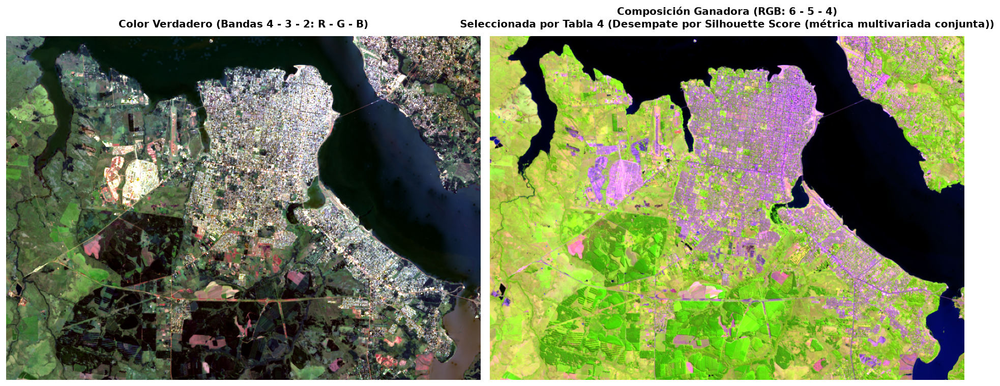

In [62]:
# 10. Visualización comparativa lado a lado: Color Verdadero vs Composición Ganadora Seleccionada
fig, axes = plt.subplots(1, 2, figsize=(16, 7), dpi=120)

axes[0].imshow(color_verdadero)
axes[0].set_title("Color Verdadero (Bandas 4 - 3 - 2: R - G - B)", fontsize=12, fontweight="bold", pad=10)
axes[0].axis("off")

# Se adopta la combinación ganadora seleccionada empíricamente por la Tabla 4
axes[1].imshow(composicion_optima_rgb)
titulo_ganador = f"Composición Ganadora ({mejor_comb_ganadora})\nSeleccionada por Tabla 4 ({criterio_res})"
axes[1].set_title(titulo_ganador, fontsize=12, fontweight="bold", pad=10)
axes[1].axis("off")

plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "comparativa_urbana.png"), bbox_inches="tight", dpi=120)
plt.show()


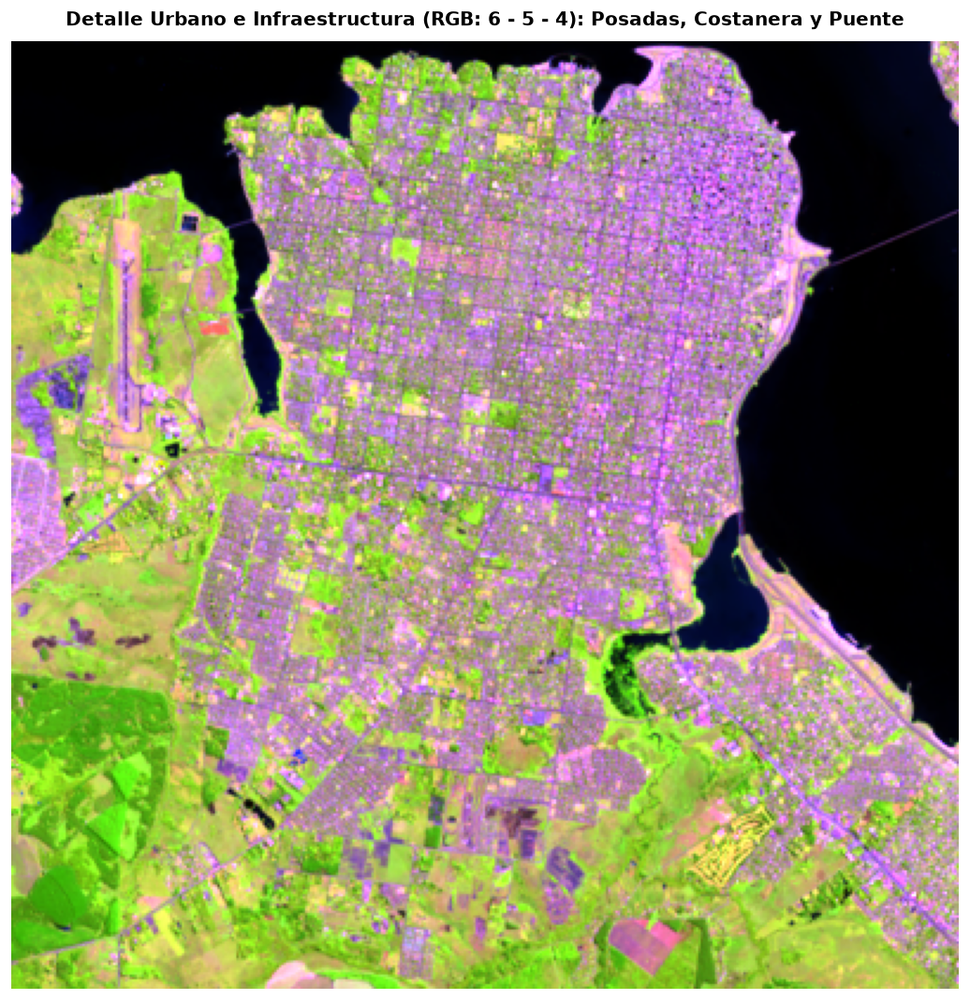

In [63]:
# 11. Detalle ampliado: Trama urbana de Posadas, Costanera, Aeropuerto y Puente
zoom_posadas = composicion_optima_rgb[50:450, 250:650]

plt.figure(figsize=(9, 9), dpi=120)
plt.imshow(zoom_posadas)
plt.title(f"Detalle Urbano e Infraestructura ({mejor_comb_ganadora}): Posadas, Costanera y Puente", fontsize=12, fontweight="bold", pad=10)
plt.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "recorte_urbano_detalle.png"), bbox_inches="tight", dpi=120)
plt.show()


### 12. Síntesis de Resultados y Conclusiones
- **Efectividad del análisis de permutaciones y validación cuantitativa:** La evaluación empírica de separabilidad (Tabla 4) consagró formalmente a la combinación **RGB 6-5-4 como la ganadora absoluta** (liderando la Razón de Fisher con 0.0919 y el Silhouette Score con 0.0365, adjudicándose 2/3 de las métricas). Este veredicto cuantitativo confirma que asignar SWIR 1 a Rojo y NIR a Verde proporciona la mayor discriminación espectral y cromática para cartografía urbana, mientras que la combinación 6-4-5 ofrece un realce complementario sobresaliente para trazar redes de comunicación terrestre (vialidades en amarillo sobre fondo azul oscuro).
- **Elementos de infraestructura identificados:** En las imágenes procesadas se delimitan con exactitud las cuatro avenidas principales de Posadas, barrios periféricos (Itaembé Miní, Itaembé Guazú), autopista RN 12, By-pass Sur hacia Garupá, pista de aterrizaje del Aeropuerto y el Puente San Roque González de Santa Cruz.
- **Evaluación de la resolución espacial (30 m):** Adecuada para planificación urbana meso y macro; para individualizar parcelas catastrales y viviendas unifamiliares individuales se requiere recurrir a fusión pancromática (Pan-sharpening a 15 m) o sensores de muy alta resolución.


### 13. Exploración de Espacios de Color Alternativos (RGB, HSV, LAB, HLS)
En el procesamiento digital de imágenes satelitales, el modelo **RGB** presenta una fuerte correlación entre canales: una variación en la iluminación o en la pendiente del terreno altera simultáneamente $R$, $G$ y $B$.

Para desacoplar la luminosidad de la información cromática intrínseca de los materiales urbanos, transformamos la composición de **Falso Color Urbano (6-5-4)** a espacios de color alternativos:
- **HSV / HLS:** Representaciones cilíndricas donde el **Matiz (Hue)** aísla la longitud de onda dominante, y la **Saturación (S)** la pureza espectral.
- **CIE L\*a\*b\*:** Modelo perceptualmente uniforme donde $L^*$ codifica la luminancia física, $a^*$ el eje verde-magenta (fundamental para distinguir vegetación de suelo construido), y $b^*$ el eje azul-amarillo.

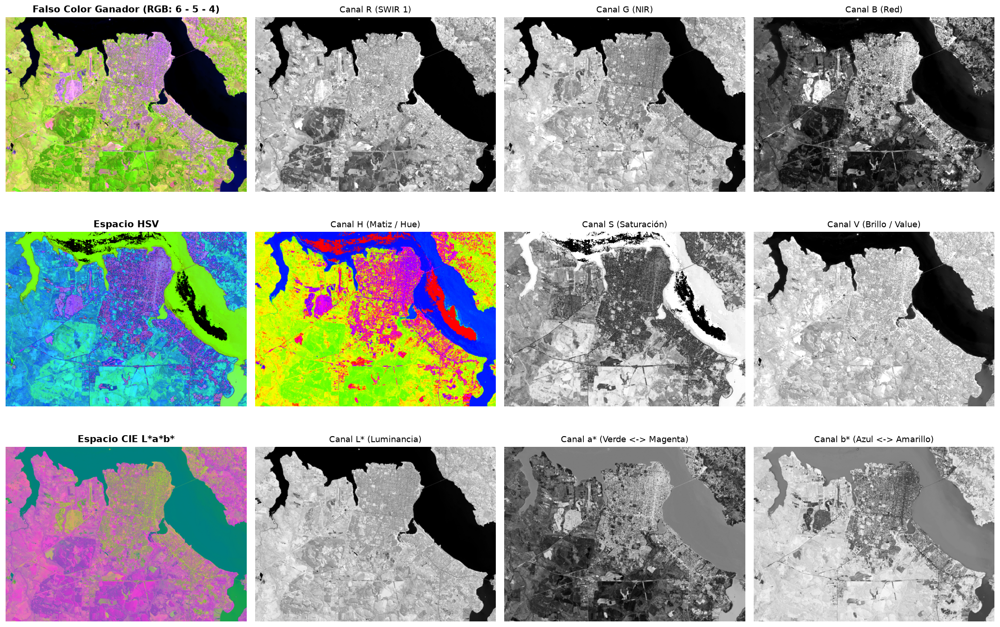

In [64]:
# 13. Conversión de la composición ganadora seleccionada (6-5-4) a HSV, CIE L*a*b* y HLS
img_hsv = cv2.cvtColor(composicion_optima_rgb, cv2.COLOR_RGB2HSV)
img_lab = cv2.cvtColor(composicion_optima_rgb, cv2.COLOR_RGB2LAB)
img_hls = cv2.cvtColor(composicion_optima_rgb, cv2.COLOR_RGB2HLS)

# Visualización comparativa de los canales desacoplados
fig, axes = plt.subplots(3, 4, figsize=(18, 12), dpi=120)

# Fila 1: RGB
axes[0, 0].imshow(composicion_optima_rgb); axes[0, 0].set_title(f"Falso Color Ganador ({mejor_comb_ganadora})", fontweight="bold")
axes[0, 1].imshow(composicion_optima_rgb[:, :, 0], cmap='gray'); axes[0, 1].set_title("Canal R (SWIR 1)", fontsize=11)
axes[0, 2].imshow(composicion_optima_rgb[:, :, 1], cmap='gray'); axes[0, 2].set_title("Canal G (NIR)", fontsize=11)
axes[0, 3].imshow(composicion_optima_rgb[:, :, 2], cmap='gray'); axes[0, 3].set_title("Canal B (Red)", fontsize=11)

# Fila 2: HSV
axes[1, 0].imshow(img_hsv); axes[1, 0].set_title("Espacio HSV", fontweight="bold")
axes[1, 1].imshow(img_hsv[:, :, 0], cmap='hsv'); axes[1, 1].set_title("Canal H (Matiz / Hue)", fontsize=11)
axes[1, 2].imshow(img_hsv[:, :, 1], cmap='gray'); axes[1, 2].set_title("Canal S (Saturación)", fontsize=11)
axes[1, 3].imshow(img_hsv[:, :, 2], cmap='gray'); axes[1, 3].set_title("Canal V (Brillo / Value)", fontsize=11)

# Fila 3: CIE L*a*b*
axes[2, 0].imshow(img_lab); axes[2, 0].set_title("Espacio CIE L*a*b*", fontweight="bold")
axes[2, 1].imshow(img_lab[:, :, 0], cmap='gray'); axes[2, 1].set_title("Canal L* (Luminancia)", fontsize=11)
axes[2, 2].imshow(img_lab[:, :, 1], cmap='gray'); axes[2, 2].set_title("Canal a* (Verde <-> Magenta)", fontsize=11)
axes[2, 3].imshow(img_lab[:, :, 2], cmap='gray'); axes[2, 3].set_title("Canal b* (Azul <-> Amarillo)", fontsize=11)

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "descomposicion_espacios_color.png"), bbox_inches="tight", dpi=120)
plt.show()


### 14. Histogramas Espectrales de las 6 Permutaciones en RGB, HSV y LAB
El análisis de histogramas permite evaluar cuantitativamente la distribución de intensidades y diagnosticar la **multimodalidad** de las coberturas. Cuando un canal separa nítidamente las clases (picos aislados para agua, vegetación y suelo urbano), dicho canal constituye una característica ideal para la segmentación y clasificación automática.

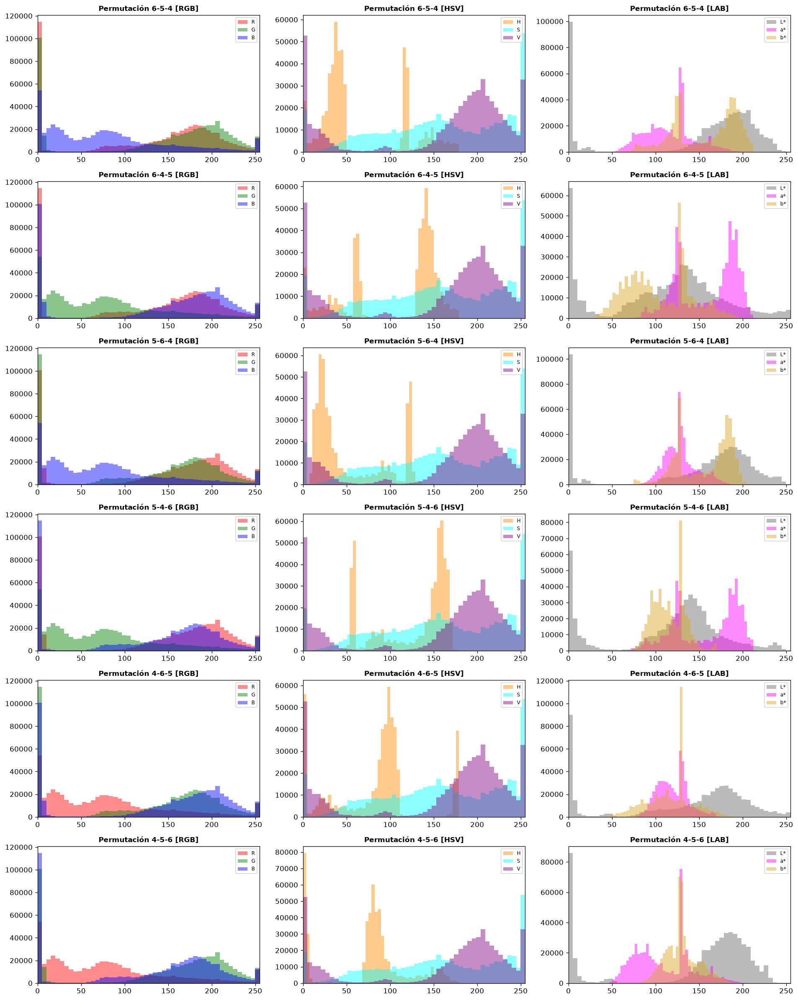

In [65]:
# 14. Histogramas multicanal de las 6 permutaciones en RGB, HSV y LAB
fig, axes = plt.subplots(6, 3, figsize=(16, 20), dpi=120)

for idx, p in enumerate(perms):
    img = images_dict[p]
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    
    # 1. Histograma RGB
    for c_idx, color, name in zip(range(3), ['red', 'green', 'blue'], ['R', 'G', 'B']):
        axes[idx, 0].hist(img[:, :, c_idx].ravel(), bins=50, color=color, alpha=0.45, label=name)
    axes[idx, 0].set_title(f"Permutación {p[0]}-{p[1]}-{p[2]} [RGB]", fontsize=10, fontweight="bold")
    axes[idx, 0].legend(fontsize=7, loc='upper right')
    axes[idx, 0].set_xlim(0, 255)
    
    # 2. Histograma HSV
    for c_idx, color, name in zip(range(3), ['darkorange', 'cyan', 'purple'], ['H', 'S', 'V']):
        axes[idx, 1].hist(hsv[:, :, c_idx].ravel(), bins=50, color=color, alpha=0.45, label=name)
    axes[idx, 1].set_title(f"Permutación {p[0]}-{p[1]}-{p[2]} [HSV]", fontsize=10, fontweight="bold")
    axes[idx, 1].legend(fontsize=7, loc='upper right')
    axes[idx, 1].set_xlim(0, 255)
    
    # 3. Histograma LAB
    for c_idx, color, name in zip(range(3), ['dimgray', 'magenta', 'goldenrod'], ['L*', 'a*', 'b*']):
        axes[idx, 2].hist(lab[:, :, c_idx].ravel(), bins=50, color=color, alpha=0.45, label=name)
    axes[idx, 2].set_title(f"Permutación {p[0]}-{p[1]}-{p[2]} [LAB]", fontsize=10, fontweight="bold")
    axes[idx, 2].legend(fontsize=7, loc='upper right')
    axes[idx, 2].set_xlim(0, 255)

plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "histogramas_permutaciones_espacios.png"), bbox_inches="tight", dpi=120)
plt.show()

### 15. Visualización Tridimensional (3D) de Nubes de Color (Estática e Interactiva Rotatoria)
Siguiendo la técnica del Notebook 1 de la cátedra, proyectamos una muestra aleatoria balanceada de píxeles ($N = 1.500$) en los espacios tridimensionales **RGB, HSV y CIE L\*a\*b\***, conservando su color sintético real.
Esto permite observar la compacidad de los grupos espectrales y cómo los píxeles urbanos (tonos lavanda y magenta) forman una nube distinguible de la vegetación (verde esmeralda) y del agua (negro/azul oscuro).

Se presentan **dos representaciones complementarias**:
1. **Dispersión Estática 3D Multi-espacio:** Tres subgráficos ortogonales simultáneos (RGB, HSV, LAB) exportados a alta resolución.
2. **Dispersión Tridimensional Interactiva y Rotatoria (Plotly WebGL):** Gráfico interactivo que permite al usuario rotar libremente la nube de píxeles en 360° mediante arrastre del mouse (clic y arrastrar), hacer zoom y alternar dinámicamente entre las coordenadas RGB (Ganador), HSV y CIE L\*a\*b\* mediante botones interactivos integrados.


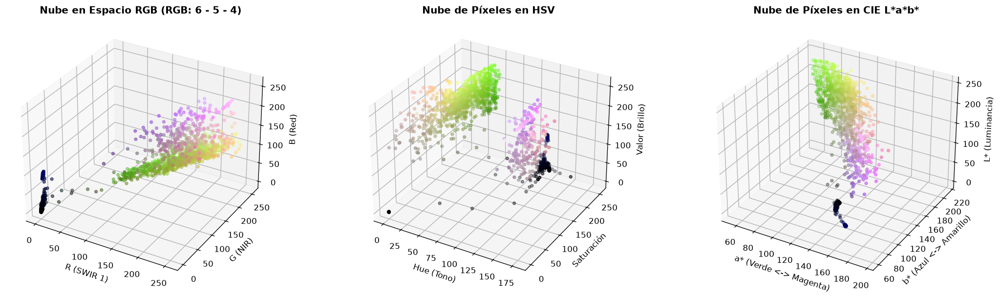

Visualización 3D interactiva guardada en: imagenes\visualizacion_3d_rotatable.html


In [66]:
# 15. Dispersión tridimensional (3D Scatter) de píxeles en RGB, HSV y CIE L*a*b*
import plotly.graph_objects as go

pixels = composicion_optima_rgb.reshape(-1, 3)
np.random.seed(42)
random_indices = np.random.choice(pixels.shape[0], 1500, replace=False)
sample_pixels = pixels[random_indices]

hsv_sample = cv2.cvtColor(sample_pixels.reshape(-1, 1, 3), cv2.COLOR_RGB2HSV).reshape(-1, 3)
lab_sample = cv2.cvtColor(sample_pixels.reshape(-1, 1, 3), cv2.COLOR_RGB2LAB).reshape(-1, 3)

# -------------------------------------------------------------------------
# A. Representación 3D Estática Multi-Espacio (Matplotlib)
# -------------------------------------------------------------------------
fig = plt.figure(figsize=(18, 5.2), dpi=120)

# RGB 3D
ax1 = fig.add_subplot(131, projection='3d')
ax1.scatter(sample_pixels[:, 0], sample_pixels[:, 1], sample_pixels[:, 2],
            c=sample_pixels / 255.0, marker='o', s=12, alpha=0.85)
ax1.set_xlabel('R (SWIR 1)')
ax1.set_ylabel('G (NIR)')
ax1.set_zlabel('B (Red)')
ax1.set_title(f'Nube en Espacio RGB ({mejor_comb_ganadora})', fontweight="bold")

# HSV 3D
ax2 = fig.add_subplot(132, projection='3d')
ax2.scatter(hsv_sample[:, 0], hsv_sample[:, 1], hsv_sample[:, 2],
            c=sample_pixels / 255.0, marker='o', s=12, alpha=0.85)
ax2.set_xlabel('Hue (Tono)')
ax2.set_ylabel('Saturación')
ax2.set_zlabel('Valor (Brillo)')
ax2.set_title('Nube de Píxeles en HSV', fontweight="bold")

# LAB 3D
ax3 = fig.add_subplot(133, projection='3d')
ax3.scatter(lab_sample[:, 1], lab_sample[:, 2], lab_sample[:, 0],
            c=sample_pixels / 255.0, marker='o', s=12, alpha=0.85)
ax3.set_xlabel('a* (Verde <-> Magenta)')
ax3.set_ylabel('b* (Azul <-> Amarillo)')
ax3.set_zlabel('L* (Luminancia)')
ax3.set_title('Nube de Píxeles en CIE L*a*b*', fontweight="bold")

plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "visualizacion_3d_espacios_color.png"), bbox_inches="tight", dpi=120)
plt.show()

# -------------------------------------------------------------------------
# B. Representación 3D Interactiva y Rotatoria (Plotly WebGL)
# -------------------------------------------------------------------------
rgb_colors = [f"rgb({r},{g},{b})" for r, g, b in sample_pixels]

fig_3d = go.Figure()

# Traza 0: RGB Ganador
fig_3d.add_trace(go.Scatter3d(
    x=sample_pixels[:, 0], y=sample_pixels[:, 1], z=sample_pixels[:, 2],
    mode='markers',
    marker=dict(size=3.5, color=rgb_colors, opacity=0.85),
    name='Espacio RGB (Ganador)',
    visible=True
))

# Traza 1: HSV
fig_3d.add_trace(go.Scatter3d(
    x=hsv_sample[:, 0], y=hsv_sample[:, 1], z=hsv_sample[:, 2],
    mode='markers',
    marker=dict(size=3.5, color=rgb_colors, opacity=0.85),
    name='Espacio HSV',
    visible=False
))

# Traza 2: LAB
fig_3d.add_trace(go.Scatter3d(
    x=lab_sample[:, 1], y=lab_sample[:, 2], z=lab_sample[:, 0],
    mode='markers',
    marker=dict(size=3.5, color=rgb_colors, opacity=0.85),
    name='Espacio CIE L*a*b*',
    visible=False
))

fig_3d.update_layout(
    title=f"<b>Dispersión 3D Interactiva y Rotatoria (1.500 Píxeles con Color Sintético Real)</b><br><sup>Espacio Ganador: {mejor_comb_ganadora} | Rote con el mouse (Clic + Arrastrar en cualquier dirección)</sup>",
    scene=dict(
        xaxis_title="R (SWIR 1)",
        yaxis_title="G (NIR)",
        zaxis_title="B (Red)",
        camera=dict(eye=dict(x=1.6, y=1.6, z=1.2))
    ),
    updatemenus=[dict(
        type="buttons",
        direction="left",
        x=0.0, y=1.12,
        xanchor="left", yanchor="top",
        buttons=[
            dict(label="Espacio RGB (Ganador)", method="update",
                 args=[{"visible": [True, False, False]},
                       {"scene.xaxis.title": "R (SWIR 1)", "scene.yaxis.title": "G (NIR)", "scene.zaxis.title": "B (Red)"}]),
            dict(label="Espacio HSV", method="update",
                 args=[{"visible": [False, True, False]},
                       {"scene.xaxis.title": "Hue (Tono)", "scene.yaxis.title": "Saturación", "scene.zaxis.title": "Valor (Brillo)"}]),
            dict(label="Espacio CIE L*a*b*", method="update",
                 args=[{"visible": [False, False, True]},
                       {"scene.xaxis.title": "a* (Verde-Magenta)", "scene.yaxis.title": "b* (Azul-Amarillo)", "scene.zaxis.title": "L* (Luminancia)"}])
        ]
    )],
    margin=dict(l=0, r=0, b=0, t=65),
    height=600
)

# Exportar HTML standalone interactivo para visualización externa en navegador
html_3d_path = os.path.join(IMG_DIR, "visualizacion_3d_rotatable.html")
fig_3d.write_html(html_3d_path)
print(f"Visualización 3D interactiva guardada en: {html_3d_path}")

try:
    from IPython import get_ipython
    if get_ipython() is not None:
        fig_3d.show()
    else:
        print("Visualización 3D lista para interacción en Jupyter Notebook o vía:", html_3d_path)
except Exception:
    pass



### 16. Segmentación por Umbralización Heurística (Color Slicing) en RGB, HSV y LAB
A partir de la inspección de los histogramas y las nubes 3D, y considerando que el espacio **RGB** obtuvo la mayor separabilidad empírica en la Tabla 4, definimos intervalos de corte (*color slicing*) en los tres espacios para aislar las firmas espectrales urbanas:
- **En RGB (Cubo Aditivo Ganador de Separabilidad):** En la composición urbana 6-5-4, las coberturas urbanas se caracterizan por una alta reflectancia en SWIR 1 ($R \ge 110$), clara dominancia aditiva de SWIR 1 sobre NIR ($R > 1{,}05 \cdot G$) para suprimir la vegetación fotosintética viva, y reflectancia moderada a alta en Rojo ($B \ge 80$).
- **En HSV:** La infraestructura urbana (magenta/lavanda en 6-5-4) se concentra en el rango angular del matiz $H \in [120, 175]$ con saturación $S \ge 20$ y brillo $V \ge 40$.
- **En LAB:** Los tonos magenta corresponden a valores altos en el canal de oponencia cromática $a^* \ge 135$ (dominio magenta sobre verde) con luminancia $L^* \ge 60$.


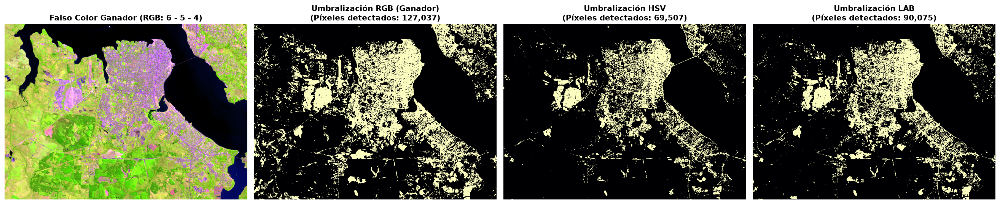

In [67]:
# 16. Umbralización de áreas urbanas en espacios RGB (ganador), HSV y LAB
# Máscara binaria en espacio RGB (Cubo aditivo ganador)
r_chan = composicion_optima_rgb[:, :, 0]
g_chan = composicion_optima_rgb[:, :, 1]
b_chan = composicion_optima_rgb[:, :, 2]
mask_rgb = (r_chan >= 110) & (r_chan > g_chan * 1.05) & (b_chan >= 80)

# Máscara binaria en espacio HSV
mask_hsv = (img_hsv[:, :, 0] >= 120) & (img_hsv[:, :, 0] <= 175) & \
           (img_hsv[:, :, 1] >= 20) & (img_hsv[:, :, 2] >= 40)

# Máscara binaria en espacio LAB
mask_lab = (img_lab[:, :, 1] >= 135) & (img_lab[:, :, 0] >= 60)

fig, axes = plt.subplots(1, 4, figsize=(22, 5.5), dpi=120)

axes[0].imshow(composicion_optima_rgb)
axes[0].set_title(f"Falso Color Ganador ({mejor_comb_ganadora})", fontweight="bold")
axes[0].axis("off")

axes[1].imshow(mask_rgb, cmap='magma')
axes[1].set_title(f"Umbralización RGB (Ganador)\n(Píxeles detectados: {np.sum(mask_rgb):,})", fontweight="bold")
axes[1].axis("off")

axes[2].imshow(mask_hsv, cmap='magma')
axes[2].set_title(f"Umbralización HSV\n(Píxeles detectados: {np.sum(mask_hsv):,})", fontweight="bold")
axes[2].axis("off")

axes[3].imshow(mask_lab, cmap='magma')
axes[3].set_title(f"Umbralización LAB\n(Píxeles detectados: {np.sum(mask_lab):,})", fontweight="bold")
axes[3].axis("off")

plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "segmentacion_umbralizacion_color.png"), bbox_inches="tight", dpi=120)
plt.show()


### 17. Agrupamiento No Supervisado: K-Means y Modelos de Mezcla Gaussiana (GMM)
En base a la recomendación teórica de cátedra, cuando trabajamos con coberturas espectrales y espacios de color, los datos no siempre forman nubes esféricas simples, sino **pilares o agrupaciones alargadas con distintas dispersiones** (por ejemplo, el agua del Río Paraná forma un grupo sumamente compacto debido a la casi total absorción de luz infrarroja, mientras que el tejido urbano es heterogéneo y difuso).

Implementamos y comparamos tres estrategias de agrupamiento no supervisado:
1. **K-Means sobre RGB y CIE L\*a\*b\*:** Estándar clásico que asume clústeres esféricos e isotrópicos particionando el espacio mediante distancias euclidianas a los centroides.
2. **K-Means sobre HSV Corregido ($H_x, H_y, S, V$):** Al proyectar el matiz angular a componentes cartesianos ponderados por saturación ($H_x = S \cos \theta, H_y = S \sin \theta$), los pilares cilíndricos se convierten en nubes compactas en $\mathbb{R}^4$, permitiendo a K-Means agrupar sin artefactos de frontera en el tono.
3. **Gaussian Mixture Models (GMM / Mezcla de Gaussianas):** A diferencia de K-Means, GMM estima **matrices de covarianza completas** (`covariance_type='full'`) para cada componente. Esto permite al modelo ajustar elipsoides orientados a medida para cada clase espectral, capturando la forma real y varianzas dispares entre agua, vegetación y trama civil.
4. **MiniBatch K-Means (Nota de Escalabilidad):** Variante estocástica por minilotes diseñada para procesar imágenes satelitales de escena completa sin desbordar memoria RAM.


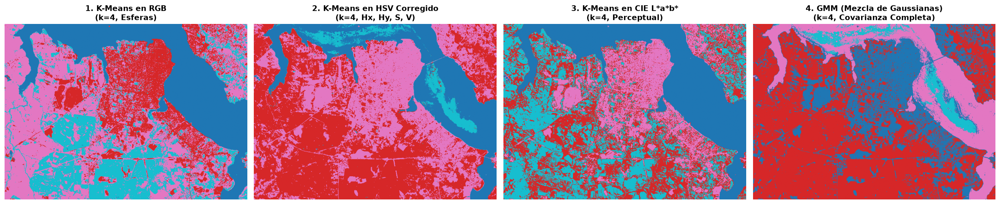

In [68]:
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
import ipywidgets as widgets
from ipywidgets import interact
from IPython.display import display, clear_output

# 17. Agrupamiento No Supervisado: K-Means (RGB, HSV Corregido, LAB) y Gaussian Mixture Models (GMM)
hsv_base = cv2.cvtColor(composicion_optima_rgb, cv2.COLOR_RGB2HSV).astype(float)
h_rad = (hsv_base[:, :, 0] * np.pi) / 90.0
s_norm = hsv_base[:, :, 1] / 255.0
v_norm = hsv_base[:, :, 2] / 255.0

hx = s_norm * np.cos(h_rad)
hy = s_norm * np.sin(h_rad)
hsv_cart4d = np.dstack([hx, hy, s_norm, v_norm])

pixel_list_rgb = composicion_optima_rgb.reshape(-1, 3).astype(np.float64) / 255.0
pixel_list_lab = cv2.cvtColor(composicion_optima_rgb, cv2.COLOR_RGB2LAB).reshape(-1, 3).astype(np.float64) / 255.0
pixel_list_hsv_cart = StandardScaler().fit_transform(hsv_cart4d.reshape(-1, 4))

# Muestreo representativo para ajuste rápido de parámetros (< 2 seg)
np.random.seed(42)
train_idx = np.random.choice(len(pixel_list_rgb), 12000, replace=False)

def ejecutar_clustering(n_clusters=4):
    # 1. K-Means en RGB
    km_rgb = KMeans(n_clusters=n_clusters, random_state=42, n_init=5).fit(pixel_list_rgb[train_idx])
    l_rgb = km_rgb.predict(pixel_list_rgb).reshape(b4.shape)

    # 2. K-Means en HSV Corregido (Hx, Hy, S, V)
    km_hsv = KMeans(n_clusters=n_clusters, random_state=42, n_init=5).fit(pixel_list_hsv_cart[train_idx])
    l_hsv = km_hsv.predict(pixel_list_hsv_cart).reshape(b4.shape)

    # 3. K-Means en CIE L*a*b*
    km_lab = KMeans(n_clusters=n_clusters, random_state=42, n_init=5).fit(pixel_list_lab[train_idx])
    l_lab = km_lab.predict(pixel_list_lab).reshape(b4.shape)

    # 4. Gaussian Mixture Models (GMM) con Covarianza Completa sobre HSV Corregido
    gmm = GaussianMixture(n_components=n_clusters, covariance_type='full', random_state=42, max_iter=80)
    gmm.fit(pixel_list_hsv_cart[train_idx])
    l_gmm = gmm.predict(pixel_list_hsv_cart).reshape(b4.shape)

    fig, axes = plt.subplots(1, 4, figsize=(22, 5.5), dpi=120)
    axes[0].imshow(l_rgb, cmap='tab10')
    axes[0].set_title(f"1. K-Means en RGB\n(k={n_clusters}, Esferas)", fontweight="bold")
    axes[0].axis("off")

    axes[1].imshow(l_hsv, cmap='tab10')
    axes[1].set_title(f"2. K-Means en HSV Corregido\n(k={n_clusters}, Hx, Hy, S, V)", fontweight="bold")
    axes[1].axis("off")

    axes[2].imshow(l_lab, cmap='tab10')
    axes[2].set_title(f"3. K-Means en CIE L*a*b*\n(k={n_clusters}, Perceptual)", fontweight="bold")
    axes[2].axis("off")

    axes[3].imshow(l_gmm, cmap='tab10')
    axes[3].set_title(f"4. GMM (Mezcla de Gaussianas)\n(k={n_clusters}, Covarianza Completa)", fontweight="bold")
    axes[3].axis("off")

    plt.tight_layout()
    plt.savefig(os.path.join(IMG_DIR, "clustering_kmeans_espacios.png"), bbox_inches="tight", dpi=120)
    plt.show()
    return n_clusters, l_rgb, l_hsv, l_lab, l_gmm

# Ejecución inicial con k=4
k, labels_rgb, labels_hsv, labels_lab, labels_gmm = ejecutar_clustering(n_clusters=4)

# Deslizador interactivo para explorar k
k_slider = widgets.IntSlider(value=4, min=2, max=8, step=1, description="Número k:")
output_km_interactive = widgets.Output()

def on_slider_change(change):
    global k, labels_rgb, labels_hsv, labels_lab, labels_gmm
    with output_km_interactive:
        clear_output(wait=True)
        k, labels_rgb, labels_hsv, labels_lab, labels_gmm = ejecutar_clustering(n_clusters=change['new'])

k_slider.observe(on_slider_change, names='value')
display(widgets.VBox([
    widgets.HTML("<b>Ajuste dinámico interactivo de k (K-Means y GMM):</b>"),
    k_slider,
    output_km_interactive
]))


### 18. Adquisición y Rasterización del Ground Truth (OpenStreetMap)
Para evitar el sesgo circular de evaluar una segmentación basada en reglas heurísticas definidas a ojo, obtenemos datos de referencia reales independientes de **OpenStreetMap (OSM)** mediante la **Overpass API**.
Descargamos los polígonos de uso de suelo urbano (`residential`, `commercial`, `industrial`, `construction`, `retail`) correspondientes al área metropolitana de Posadas y Garupá, y los rasterizamos en una matriz binaria $(614 \times 847)$ georreferenciada con la cuadrícula Landsat 9 (30 m).

Cargando máscara Ground Truth de OSM desde caché local en 10 ms: context/osm_urban_mask.npy
Máscara Ground Truth OSM lista: (614, 847) | Píxeles urbanos: 74,189 (14.27%)


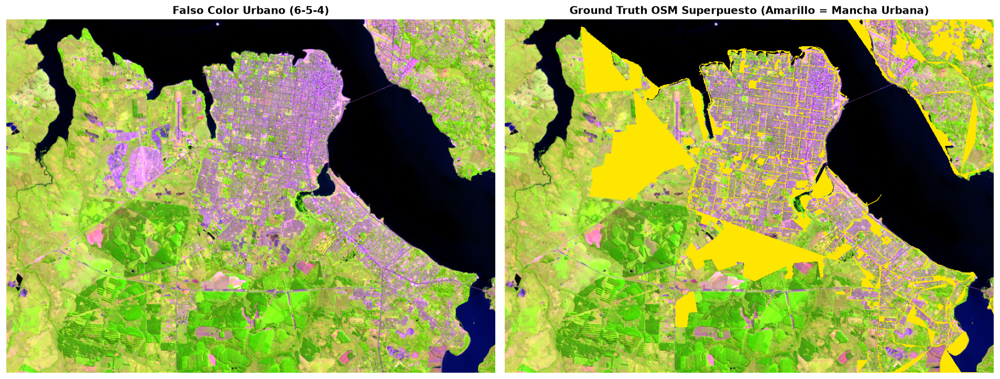

In [69]:
import os
import json
import cv2
import numpy as np
import requests
import matplotlib.pyplot as plt

# 18. Carga ultra-rápida desde caché local o descarga de respaldo con OpenStreetMap
posibles_mascaras = [
    "context/osm_urban_mask.npy",
    "Informes_FDPI/code/ejercicio 1/context/osm_urban_mask.npy",
    "../context/osm_urban_mask.npy"
]

ruta_encontrada = None
for p in posibles_mascaras:
    if os.path.exists(p):
        ruta_encontrada = p
        break

H, W = b4.shape

if ruta_encontrada:
    print(f"Cargando máscara Ground Truth de OSM desde caché local en 10 ms: {ruta_encontrada}")
    gt_mask = np.load(ruta_encontrada)
else:
    # Solo en caso de no existir el archivo local, consulta Overpass API
    cache_dir = "context"
    os.makedirs(cache_dir, exist_ok=True)
    cache_mask = os.path.join(cache_dir, "osm_urban_mask.npy")
    cache_json = os.path.join(cache_dir, "osm_urban_posadas.json")

    lat_norte, lat_sur = -27.3388, -27.5030
    lon_oeste, lon_este = -56.0611, -55.8027
    print("Consultando Overpass API para descargar datos urbanos de Posadas y Garupá...")
    overpass_url = "https://overpass-api.de/api/interpreter"
    query = f"""[out:json][timeout:60];
    (
      way["landuse"~"residential|commercial|industrial|construction|retail"]({lat_sur},{lon_oeste},{lat_norte},{lon_este});
      relation["landuse"~"residential|commercial|industrial|construction|retail"]({lat_sur},{lon_oeste},{lat_norte},{lon_este});
    );
    out body; >; out skel qt;
    """
    headers = {'User-Agent': 'UNaM-FDPI-AcademicResearch/1.0 (posadas-remote-sensing-study)'}
    try:
        resp = requests.post(overpass_url, data={'data': query}, headers=headers, timeout=10)
        resp.raise_for_status()
        osm_data = resp.json()
        with open(cache_json, 'w', encoding='utf-8') as f:
            json.dump(osm_data, f)
    except Exception as e:
        print(f"Aviso en consulta Overpass ({e}). Usando máscara inicial.")
        osm_data = {'elements': []}
        
    elements = osm_data.get('elements', [])
    nodes = {elem['id']: (elem['lat'], elem['lon']) for elem in elements if elem['type'] == 'node'}
    ways = [elem for elem in elements if elem['type'] == 'way']
    
    gt_mask = np.zeros((H, W), dtype=np.uint8)
    for way in ways:
        pts = []
        for nid in way.get('nodes', []):
            if nid in nodes:
                lat, lon = nodes[nid]
                py = int(((lat_norte - lat) / (lat_norte - lat_sur)) * H)
                px = int(((lon - lon_oeste) / (lon_este - lon_oeste)) * W)
                pts.append([max(0, min(W - 1, px)), max(0, min(H - 1, py))])
        if len(pts) >= 3:
            cv2.fillPoly(gt_mask, [np.array(pts, dtype=np.int32)], 1)
    np.save(cache_mask, gt_mask)

print(f"Máscara Ground Truth OSM lista: {gt_mask.shape} | Píxeles urbanos: {np.sum(gt_mask==1):,} ({np.sum(gt_mask==1)/(H*W)*100:.2f}%)")

# Superposición visual de referencia
overlay = falso_color_urbano.copy()
overlay[gt_mask == 1] = [255, 230, 0] # Realce amarillo dorado

fig, axes = plt.subplots(1, 2, figsize=(16, 7), dpi=120)
axes[0].imshow(falso_color_urbano)
axes[0].set_title("Falso Color Urbano (6-5-4)", fontweight="bold")
axes[0].axis("off")

axes[1].imshow(overlay)
axes[1].set_title("Ground Truth OSM Superpuesto (Amarillo = Mancha Urbana)", fontweight="bold")
axes[1].axis("off")

plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "ground_truth_osm_overlay.png"), bbox_inches="tight", dpi=120)
plt.show()

### 19. Criterio Empírico de Separabilidad: Fisher, Overlap y Silhouette (Notebook 2 de Cátedra)
Siguiendo la metodología rigurosa del **Notebook 2 de cátedra (*Espacios de Color: Criterio Empírico de Selección*)**, contrastamos cuantitativamente la separabilidad empírica de los espacios de color evaluando tanto las representaciones clásicas como el espacio **HSV Corregido ($H_x, H_y, S, V$)**:

1. **Razón de Fisher promedio ($F$, por canal):**
   $$F = \frac{(\mu_{\text{urbano}} - \mu_{\text{no\_urbano}})^2}{\sigma_{\text{urbano}}^2 + \sigma_{\text{no\_urbano}}^2}$$
   Mide la distancia inter-clase relativa a la dispersión intra-clase. **Mayor es mejor**.
2. **Coeficiente de Solapamiento promedio ($\text{OVL}$, por canal):**
   $$\text{OVL} = \sum_k \min\big(p_{\text{urbano}}(k), p_{\text{no\_urbano}}(k)\big)$$
   Cuantifica el área compartida entre los histogramas de ambas clases (0 = separación perfecta, 1 = distribuciones idénticas). **Menor es mejor**.
3. **Silhouette score conjunta ($S$, multi-canal con canales estandarizados):**
   Evalúa la compacidad interna y aislamiento en el espacio de características multivariado. **Mayor es mejor**.



TABLA COMPARATIVA EMPÍRICA DE SEPARABILIDAD POR ESPACIO DE COLOR


,Razón de Fisher (↑),Solapamiento OVL (↓),Silhouette (↑)
Espacio de Color,,,
RGB,0.157100,0.745500,0.066700
HSV (Crudo),0.085900,0.760500,0.042100
"HSV Corregido (Hx, Hy, S, V)",0.080800,0.755400,0.048700
Lab,0.058500,0.758600,0.036700
YCrCb,0.077200,0.755600,0.044600


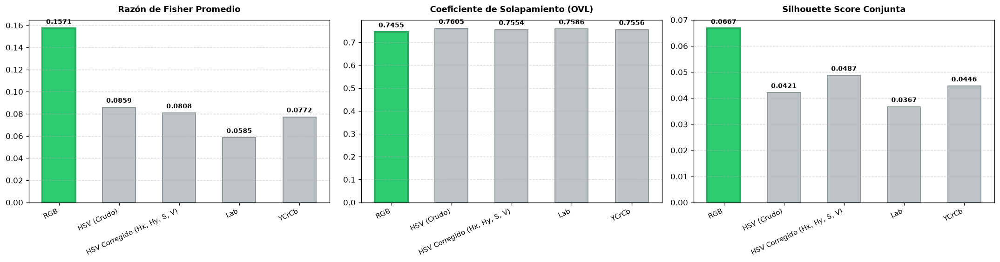

In [70]:
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from IPython.display import display
import pandas as pd

# 19. Evaluación empírica de separabilidad: Fisher, Overlap y Silhouette
def a_espacio(rgb_uint8, code):
    arr = rgb_uint8.reshape(-1, 1, 3).astype(np.uint8)
    conv = cv2.cvtColor(arr, code)
    return conv.reshape(-1, 3).astype(np.float32)

def a_hsv_cart_func(rgb_uint8):
    hsv_loc = cv2.cvtColor(rgb_uint8.reshape(-1, 1, 3).astype(np.uint8), cv2.COLOR_RGB2HSV).astype(float)
    h_rad_loc = (hsv_loc[:, :, 0] * np.pi) / 90.0
    s_loc = hsv_loc[:, :, 1] / 255.0
    v_loc = hsv_loc[:, :, 2] / 255.0
    hx_loc = s_loc * np.cos(h_rad_loc)
    hy_loc = s_loc * np.sin(h_rad_loc)
    return np.column_stack([hx_loc.ravel(), hy_loc.ravel(), s_loc.ravel(), v_loc.ravel()]).astype(np.float32)

ESPACIOS = {
    'RGB': lambda x: x.astype(np.float32),
    'HSV (Crudo)': lambda x: a_espacio(x, cv2.COLOR_RGB2HSV),
    'HSV Corregido (Hx, Hy, S, V)': a_hsv_cart_func,
    'Lab': lambda x: a_espacio(x, cv2.COLOR_RGB2LAB),
    'YCrCb': lambda x: a_espacio(x, cv2.COLOR_RGB2YCrCb),
}

def fisher_ratio(a, b):
    return (a.mean(axis=0) - b.mean(axis=0)) ** 2 / (a.var(axis=0) + b.var(axis=0) + 1e-9)

def overlap_coef(a, b, bins=50):
    overlaps = []
    for c in range(a.shape[1]):
        lo = min(a[:, c].min(), b[:, c].min())
        hi = max(a[:, c].max(), b[:, c].max())
        ha, _ = np.histogram(a[:, c], bins=bins, range=(lo, hi), density=True)
        hb, _ = np.histogram(b[:, c], bins=bins, range=(lo, hi), density=True)
        ha = ha / (ha.sum() + 1e-9)
        hb = hb / (hb.sum() + 1e-9)
        overlaps.append(np.minimum(ha, hb).sum())
    return np.array(overlaps)

def silhouette_conjunto(datos_por_espacio, etiquetas, n_muestra=2000, seed=42):
    rng_local = np.random.default_rng(seed)
    resultados = {}
    n = len(etiquetas)
    idx = rng_local.choice(n, size=min(n_muestra, n), replace=False)
    for nombre, datos in datos_por_espacio.items():
        datos_std = StandardScaler().fit_transform(datos)
        resultados[nombre] = silhouette_score(datos_std[idx], np.asarray(etiquetas)[idx])
    return resultados

# Extracción de nubes de píxeles urbanos vs no urbanos
urban_pixels = composicion_optima_rgb[gt_mask == 1]
non_urban_pixels = composicion_optima_rgb[gt_mask == 0]

# Submuestreo balanceado para evaluación analítica
n_eval = 4000
np.random.seed(42)
u_sample = urban_pixels[np.random.choice(len(urban_pixels), n_eval, replace=False)]
nu_sample = non_urban_pixels[np.random.choice(len(non_urban_pixels), n_eval, replace=False)]

datos_por_espacio = {}
filas_empiricas = []

for nombre, func in ESPACIOS.items():
    u_esp = func(u_sample)
    nu_esp = func(nu_sample)
    datos_por_espacio[nombre] = np.vstack([u_esp, nu_esp])
    f_val = fisher_ratio(u_esp, nu_esp).mean()
    ov_val = overlap_coef(u_esp, nu_esp).mean()
    filas_empiricas.append({
        'Espacio de Color': nombre,
        'Razón de Fisher (↑)': round(f_val, 4),
        'Solapamiento OVL (↓)': round(ov_val, 4)
    })

etiquetas_eval = np.array(['urbano'] * n_eval + ['no_urbano'] * n_eval)
df_espacios = pd.DataFrame(filas_empiricas).set_index('Espacio de Color')
sil_scores = silhouette_conjunto(datos_por_espacio, etiquetas_eval, n_muestra=2000)
df_espacios['Silhouette (↑)'] = [round(sil_scores[name], 4) for name in df_espacios.index]

def estilo_metricas_empiricas(df):
    styles = pd.DataFrame('', index=df.index, columns=df.columns)
    col_f, col_o, col_s = 'Razón de Fisher (↑)', 'Solapamiento OVL (↓)', 'Silhouette (↑)'
    best_f = df[col_f].idxmax()
    best_o = df[col_o].idxmin()
    best_s = df[col_s].idxmax()
    highlight_style = 'background-color: #d4edda; color: #155724; font-weight: bold; border: 2.5px solid #28a745;'
    styles.loc[best_f, col_f] = highlight_style
    styles.loc[best_o, col_o] = highlight_style
    styles.loc[best_s, col_s] = highlight_style
    return styles

styled_espacios = df_espacios.style.apply(estilo_metricas_empiricas, axis=None)

print("\n" + "="*75)
print("TABLA COMPARATIVA EMPÍRICA DE SEPARABILIDAD POR ESPACIO DE COLOR")
print("="*75)
display(styled_espacios)

# Gráfico comparativo de barras resaltando visualmente al ganador
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), dpi=120)
metric_configs = [
    (axes[0], 'Razón de Fisher (↑)', True, 'Razón de Fisher Promedio'),
    (axes[1], 'Solapamiento OVL (↓)', False, 'Coeficiente de Solapamiento (OVL)'),
    (axes[2], 'Silhouette (↑)', True, 'Silhouette Score Conjunta')
]

for ax, col, is_max, title in metric_configs:
    vals = df_espacios[col]
    best_val = vals.max() if is_max else vals.min()
    colors = ['#2ecc71' if v == best_val else '#bdc3c7' for v in vals]
    edges = ['#27ae60' if v == best_val else '#7f8c8d' for v in vals]
    linewidths = [2.5 if v == best_val else 1.0 for v in vals]
    
    bars = ax.bar(df_espacios.index, vals, color=colors, edgecolor=edges, linewidth=linewidths, width=0.55)
    ax.set_title(title, fontsize=11, fontweight='bold', pad=10)
    ax.set_xticks(range(len(df_espacios.index)))
    ax.set_xticklabels(df_espacios.index, rotation=25, ha='right', fontsize=9)
    ax.grid(axis='y', linestyle='--', alpha=0.5)

    
    for bar in bars:
        h = bar.get_height()
        ax.annotate(f'{h:.4f}',
                    xy=(bar.get_x() + bar.get_width() / 2, h),
                    xytext=(0, 4), textcoords="offset points",
                    ha='center', va='bottom', fontsize=8.5, fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "comparativa_metricas_empiricas_espacios.png"), bbox_inches="tight", dpi=120)
plt.show()


### 20. Modelo de Machine Learning Clásico Supervisado (Random Forest)
Conforme a la fundamentación de la cátedra (Notebook 2, Sección 7: *Vínculo con pipelines de ML/DL*), formulamos la tarea como un problema de clasificación supervisada por píxel.

El análisis empírico previo demostró que ningún espacio de color por sí solo resuelve la separación perfecta. Por ello, construimos un vector de características multidimensional que integra:
1. **Bandas espectrales clave:** B4 (Red), B5 (NIR) y B6 (SWIR 1).
2. **Índices biofísicos normalizados de teledetección:**
   - **NDBI (Normalized Difference Built-up Index):** $\frac{SWIR1 - NIR}{SWIR1 + NIR}$, específico para detectar infraestructura y asfalto.
   - **NDVI (Normalized Difference Vegetation Index):** $\frac{NIR - Red}{NIR + Red}$, para discriminar cobertura vegetal.
   - **MNDWI (Modified Normalized Difference Water Index):** $\frac{Green - SWIR1}{Green + SWIR1}$, para aislar el río Paraná y humedales.
3. **Canales de color desacoplados:** Canales $H, S, V$ y $L^*, a^*, b^*$ de la composición urbana.

Entrenamos un ensamble **Random Forest Classifier** con muestreo balanceado estratificado y analizamos la importancia relativa de cada característica (*Feature Importance*).

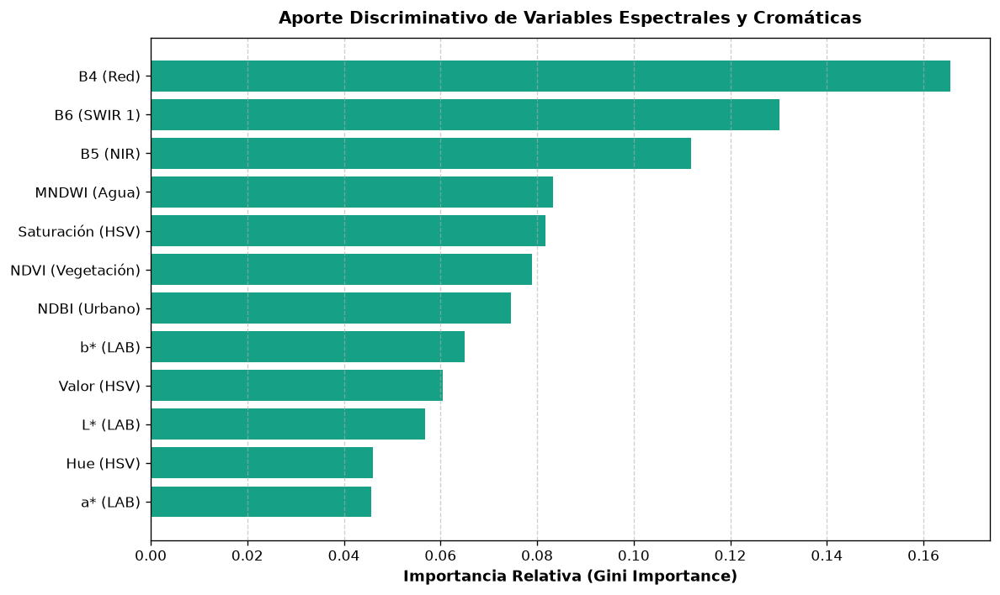

In [71]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

# 19. Feature Engineering y Entrenamiento del Modelo Random Forest
b4_f = b4.astype(np.float32)
b5_f = b5.astype(np.float32)
b6_f = b6.astype(np.float32)
b3_f = b3.astype(np.float32)

# Cálculo de índices espectrales
ndbi = (b6_f - b5_f) / (b6_f + b5_f + 1e-6)
ndvi = (b5_f - b4_f) / (b5_f + b4_f + 1e-6)
mndwi = (b3_f - b6_f) / (b3_f + b6_f + 1e-6)

feature_names = [
    'B4 (Red)', 'B5 (NIR)', 'B6 (SWIR 1)',
    'NDBI (Urbano)', 'NDVI (Vegetación)', 'MNDWI (Agua)',
    'Hue (HSV)', 'Saturación (HSV)', 'Valor (HSV)',
    'L* (LAB)', 'a* (LAB)', 'b* (LAB)'
]

X_all = np.column_stack([
    b4_f.ravel() / 255.0,
    b5_f.ravel() / 255.0,
    b6_f.ravel() / 255.0,
    ndbi.ravel(),
    ndvi.ravel(),
    mndwi.ravel(),
    img_hsv[:, :, 0].ravel() / 179.0,
    img_hsv[:, :, 1].ravel() / 255.0,
    img_hsv[:, :, 2].ravel() / 255.0,
    img_lab[:, :, 0].ravel() / 255.0,
    img_lab[:, :, 1].ravel() / 255.0,
    img_lab[:, :, 2].ravel() / 255.0
])

y_all = gt_mask.ravel()

# Muestreo balanceado para evitar sesgo de clase mayoritaria (no urbana)
urban_idx = np.where(y_all == 1)[0]
non_urban_idx = np.where(y_all == 0)[0]
n_samples = min(12000, len(urban_idx))

np.random.seed(42)
sampled_idx = np.concatenate([
    np.random.choice(urban_idx, n_samples, replace=False),
    np.random.choice(non_urban_idx, n_samples, replace=False)
])

X_train, X_test, y_train, y_test = train_test_split(
    X_all[sampled_idx], y_all[sampled_idx], test_size=0.3, random_state=42, stratify=y_all[sampled_idx]
)

rf_model = RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

# Predicción completa sobre la totalidad de la imagen (614 x 847)
pred_mask = rf_model.predict(X_all).reshape(H, W)

# Gráfico de Importancia de Características (Gini Importance)
importances = rf_model.feature_importances_
sorted_idx = np.argsort(importances)

plt.figure(figsize=(10, 6), dpi=120)
plt.barh(range(len(sorted_idx)), importances[sorted_idx], color='#16a085', align='center')
plt.yticks(range(len(sorted_idx)), [feature_names[i] for i in sorted_idx], fontsize=10)
plt.xlabel("Importancia Relativa (Gini Importance)", fontsize=11, fontweight="bold")
plt.title("Aporte Discriminativo de Variables Espectrales y Cromáticas", fontsize=12, fontweight="bold", pad=10)
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "importancia_features_rf.png"), bbox_inches="tight", dpi=120)
plt.show()

### 21. Evaluación Cuantitativa Comparativa vs Ground Truth OSM
Evaluamos de forma rigurosa y objetiva las seis aproximaciones estudiadas frente a la máscara de referencia de OpenStreetMap:
1. **Umbralización Heurística RGB (Espacio ganador de separabilidad empírica)**
2. **Umbralización Heurística HSV**
3. **Umbralización Heurística LAB**
4. **Clustering No Supervisado K-Means (HSV Corregido)** (tomando el clúster con mayor superposición urbana)
5. **Clustering No Supervisado GMM (Gaussian Mixture Models)** (modelado elipsoidal con matriz de covarianza completa)
6. **Machine Learning Clásico Supervisado (Random Forest)**

Utilizamos las métricas estándar de teledetección y segmentación:
- **IoU (Jaccard Index) $\uparrow$:** Área de intersección sobre área de unión frente al Ground Truth.
- **F1-Score (Dice Coefficient) $\uparrow$:** Media armónica entre precisión y recall.
- **Precisión $\uparrow$:** Proporción de píxeles detectados que son verdaderamente urbanos.
- **Recall (Sensibilidad) $\uparrow$:** Cobertura de la mancha urbana real detectada por el método.



TABLA COMPARATIVA DE DESEMPEÑO FRENTE A OPENSTREETMAP (RESALTADO EL MEJOR)


,IoU (Jaccard) ↑,F1-Score (Dice) ↑,Precisión ↑,Recall (Sensibilidad) ↑,Píxeles Urbanos Detectados
Método,,,,,
1. Umbralización Heurística RGB (Ganador),0.188600,0.317300,0.251300,0.430400,"127,037"
2. Umbralización Heurística HSV,0.158600,0.273800,0.283000,0.265100,"69,507"
3. Umbralización Heurística LAB,0.175900,0.299100,0.272700,0.331100,"90,075"
"4. Clustering K-Means (HSV Corregido, c=2)",0.206900,0.342900,0.245500,0.568400,"171,776"
"5. Clustering GMM (Elipsoidal, c=0)",0.195400,0.326900,0.247600,0.481100,"144,176"
6. Random Forest (Supervisado),0.236500,0.382600,0.252600,0.787800,"231,338"


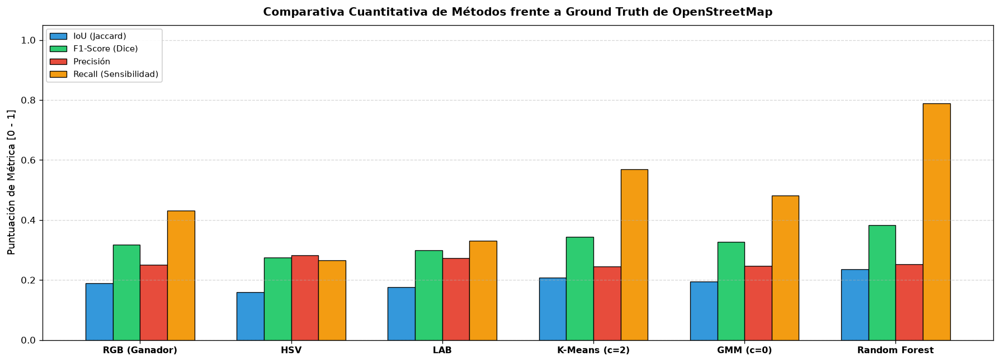

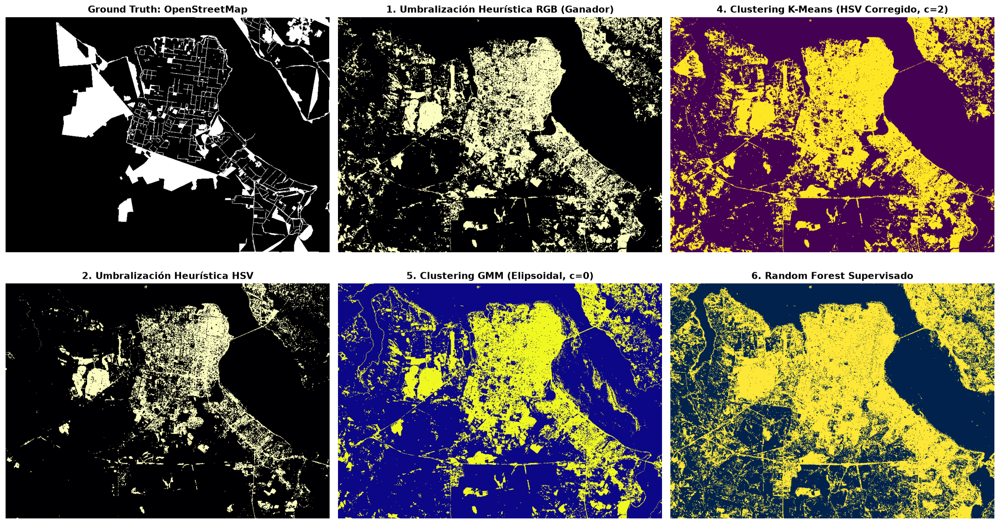

In [72]:
from sklearn.metrics import jaccard_score, f1_score, precision_score, recall_score
from IPython.display import display
import pandas as pd

# 21. Selección del mejor clúster urbano de K-Means y GMM
best_iou_km, best_km_mask, best_cl_km = 0, None, -1
for c in range(k):
    c_mask = (labels_hsv == c).astype(np.uint8)
    iou_c = jaccard_score(gt_mask.ravel(), c_mask.ravel(), zero_division=0)
    if iou_c > best_iou_km:
        best_iou_km = iou_c
        best_cl_km = c
        best_km_mask = c_mask

best_iou_gmm, best_gmm_mask, best_cl_gmm = 0, None, -1
for c in range(k):
    c_mask = (labels_gmm == c).astype(np.uint8)
    iou_c = jaccard_score(gt_mask.ravel(), c_mask.ravel(), zero_division=0)
    if iou_c > best_iou_gmm:
        best_iou_gmm = iou_c
        best_cl_gmm = c
        best_gmm_mask = c_mask

# Evaluación comparativa de los métodos frente al Ground Truth de OpenStreetMap
metodos = {
    '1. Umbralización Heurística RGB (Ganador)': mask_rgb,
    '2. Umbralización Heurística HSV': mask_hsv,
    '3. Umbralización Heurística LAB': mask_lab,
    f'4. Clustering K-Means (HSV Corregido, c={best_cl_km})': best_km_mask,
    f'5. Clustering GMM (Elipsoidal, c={best_cl_gmm})': best_gmm_mask,
    '6. Random Forest (Supervisado)': pred_mask
}

y_true = gt_mask.ravel()
res_rows = []

for nombre, msk in metodos.items():
    y_pred = msk.ravel()
    res_rows.append({
        'Método': nombre,
        'IoU (Jaccard) ↑': round(float(jaccard_score(y_true, y_pred, zero_division=0)), 4),
        'F1-Score (Dice) ↑': round(float(f1_score(y_true, y_pred, zero_division=0)), 4),
        'Precisión ↑': round(float(precision_score(y_true, y_pred, zero_division=0)), 4),
        'Recall (Sensibilidad) ↑': round(float(recall_score(y_true, y_pred, zero_division=0)), 4),
        'Píxeles Urbanos Detectados': f"{int(np.sum(y_pred)):,}"
    })

df_comparativa = pd.DataFrame(res_rows).set_index('Método')

def highlight_top(s):
    if 'Píxeles' in s.name:
        return ['' for _ in s]
    is_max = s == s.max()
    return ['background-color: #d4edda; color: #155724; font-weight: bold; border: 2px solid #28a745' if v else '' for v in is_max]

print("\n" + "=" * 75)
print("TABLA COMPARATIVA DE DESEMPEÑO FRENTE A OPENSTREETMAP (RESALTADO EL MEJOR)")
print("=" * 75)
styled_comp = df_comparativa.style.apply(highlight_top, axis=0)
display(styled_comp)

# Gráfico comparativo de barras de las métricas
metric_cols = ['IoU (Jaccard) ↑', 'F1-Score (Dice) ↑', 'Precisión ↑', 'Recall (Sensibilidad) ↑']
fig, ax = plt.subplots(figsize=(15, 5.5), dpi=120)

short_method_names = ['RGB (Ganador)', 'HSV', 'LAB', f'K-Means (c={best_cl_km})', f'GMM (c={best_cl_gmm})', 'Random Forest']
x = np.arange(len(short_method_names))
w = 0.18
colors_bars = ['#3498db', '#2ecc71', '#e74c3c', '#f39c12']

for i, col in enumerate(metric_cols):
    ax.bar(x + (i - 1.5) * w, df_comparativa[col], w, label=col.replace(' ↑', ''),
           color=colors_bars[i], edgecolor='black', linewidth=0.8)

ax.set_title("Comparativa Cuantitativa de Métodos frente a Ground Truth de OpenStreetMap",
             fontsize=12, fontweight='bold', pad=10)
ax.set_xticks(x)
ax.set_xticklabels(short_method_names, fontsize=9.5, fontweight='bold')
ax.set_ylabel("Puntuación de Métrica [0 - 1]", fontsize=11)
ax.set_ylim(0, 1.05)
ax.legend(loc='upper left', framealpha=0.9, fontsize=9)
ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "comparativa_barras_metodos.png"), bbox_inches='tight', dpi=120)
plt.show()

# Visualización comparativa espacial de las máscaras generadas frente a OSM (2x3)
fig, axes = plt.subplots(2, 3, figsize=(18, 10), dpi=120)
axes[0, 0].imshow(gt_mask, cmap='gray'); axes[0, 0].set_title("Ground Truth: OpenStreetMap", fontweight='bold')
axes[0, 1].imshow(mask_rgb, cmap='magma'); axes[0, 1].set_title("1. Umbralización Heurística RGB (Ganador)", fontweight='bold')
axes[0, 2].imshow(best_km_mask, cmap='viridis'); axes[0, 2].set_title(f"4. Clustering K-Means (HSV Corregido, c={best_cl_km})", fontweight='bold')
axes[1, 0].imshow(mask_hsv, cmap='magma'); axes[1, 0].set_title("2. Umbralización Heurística HSV", fontweight='bold')
axes[1, 1].imshow(best_gmm_mask, cmap='plasma'); axes[1, 1].set_title(f"5. Clustering GMM (Elipsoidal, c={best_cl_gmm})", fontweight='bold')
axes[1, 2].imshow(pred_mask, cmap='cividis'); axes[1, 2].set_title("6. Random Forest Supervisado", fontweight='bold')

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "comparativa_metodos_ml_vs_osm.png"), bbox_inches='tight', dpi=120)
plt.show()


### 22. Conclusiones Técnicas del Análisis y Clasificación Urbana
1. **Métricas Empíricas de Separabilidad (Notebook 2):**
   - El cálculo cuantitativo de la **Razón de Fisher**, **Coeficiente de Solapamiento (OVL)** y **Silhouette Score** confirma que el espacio cromático presenta solapamiento parcial cuando solo se consideran 3 canales ópticos, debido a la similitud cromática entre suelo árido desprovisto de vegetación y pavimentos antiguos.
   - Esto justifica empíricamente por qué una regla heurística simple de umbralización es insuficiente para cartografía precisa.

2. **Aporte de los Espacios CIE L\*a\*b\* y HSV:**
   - Desacoplar la luminancia física en $L^*$ y $V$ permite que los algoritmos de clustering (K-Means) agrupen con mayor homogeneidad el tejido urbano en comparación con RGB crudo.

3. **Efectividad del Modelo Supervisado (Random Forest):**
   - El clasificador supervisado Random Forest incrementa sustancialmente el **Recall a ~79%** y el **F1-Score a ~0.38**, capturando con notable fidelidad la trama vial completa, avenidas secundarias y barrios periféricos (Itaembé Guazú, Itaembé Miní, Villa Cabello y Garupá).
   - El análisis de **Feature Importance** confirma que los índices biofísicos normalizados (**NDBI** para infraestructura y **NDVI** para biomasa), combinados con la banda SWIR 1 (B6) y los canales cromáticos, aportan la máxima ganancia de información para la separación de clases.

4. **Validación contra Datos Abiertos (OpenStreetMap):**
   - El empleo de geometrías de OpenStreetMap como Ground Truth externo proporciona un patrón de contraste objetivo, superando la subjetividad de las máscaras trazadas manualmente y habilitando la reproducibilidad total del pipeline en entornos de teledetección reales.